# Experimento da escada de calibração T0.5 — benchmark de descoberta causal

**Rafael Silva Ennes** — Universidade Presbiteriana Mackenzie

---

## Objetivo

O harness `new_pipe_dag` foi desenhado em torno de três propostas: (i) diagnosticar o dado
antes de responsabilizar o algoritmo, (ii) reportar métricas **estratificadas por tipo de
aresta** em vez de um F1 agregado, e (iii) rodar uma **escada de calibração** em que cada
degrau liga um único fator de dificuldade por vez.

Até aqui, apenas (i) e (ii) produziram evidência: todos os resultados registrados em
`new_pipe_dag/results/` vêm do preset realista `causal_business`. **A escada L0–L8 nunca
foi executada.** Sem ela não é possível responder à pergunta central do capítulo — *qual
fator específico (ruído, tamanho amostral, adstock, saturação, sazonalidade latente,
colinearidade) faz cada método colapsar* — porque no preset realista todos os fatores estão
ligados simultaneamente.

Este notebook executa o experimento completo e produz as evidências faltantes.

## Perguntas de pesquisa

| # | Pergunta | Evidência que a responde |
|---|---|---|
| **Q1** | Em qual degrau da escada cada algoritmo colapsa? | Fig. 1 (F1 × nível) e Fig. 6 (heatmap) |
| **Q2** | O recall baixo em cenários sazonais é falha do método ou limite do desenho? | Fig. 2 (recall vs. `recall_ceiling` analítico) |
| **Q3** | O eixo da escada é de fato um eixo de dificuldade crescente? | Fig. 3 (diagnósticos × nível) |
| **Q4** | Onde os métodos erram — deixam de achar arestas reais ou inventam arestas? | Fig. 4 (falsos positivos por estrato) |
| **Q5** | Métodos que inventam efeito em canais sem efeito algum? | Bloco D (canais fantasma) + Fig. 4 |
| **Q6** | O custo computacional se justifica pelo ganho de qualidade? | Fig. 5 (runtime, escala log) |
| **Q7** | Os algoritmos que devolvem grafo vazio têm baixo desempenho ou estão quebrados? | §12 e §13 (evidência de falha) |

## Estrutura da execução

O experimento é dividido em blocos com custos muito diferentes. **Cada bloco é retomável**:
se a execução for interrompida, basta reexecutar — as combinações já registradas em
`runs.csv` são puladas.

| Bloco | O que roda | Custo | Onde executar |
|---|---|---|---|
| **A** | `granger`, `dynotears`, `lpcmci` em L0–L8 × 5 seeds | ~4 min | interativo |
| **B** | `cedar`, `rpcmci` em L2–L8 × 5 seeds | ~45 min | tmux |
| **C** | `pcmci_cmiknn`, `cdnots`, `regime_pcmci` em L2/L6/L8 × 3 seeds | **~5,5 h** | tmux, noturno |
| **D** | Baratos em L2g/L8g (canais fantasma) × 5 seeds | ~20 min | tmux |
| **E** | Preset `causal_business`, `v1_legacy` e `v2` × 3 seeds | ~15 min | tmux |
| **Figuras** | Reconstruídas a partir do `runs.csv` | <1 min | interativo |

O bloco C está atrás do interruptor `RODAR_CAROS`, desligado por padrão. Com ele desligado,
uma reexecução completa do notebook reconstrói todas as figuras em menos de um minuto.

## ⚠️ Pré-requisito de ambiente

Este `.venv` está sobre Nix e **não importa `numpy`/`pandas`/`matplotlib` sem
`LD_LIBRARY_PATH`**. Antes de subir o Jupyter (ou de rodar via `nbconvert`):

```bash
export LD_LIBRARY_PATH=/nix/store/ybp235ps7m4yd85v0pgvqkhd4xmxf6jq-gcc-14.3.0-lib/lib:/nix/store/lf793zr9yfa0dpph8jlxbbdnvnahvq8b-zlib-1.3.2/lib
```

Sem isso o kernel morre em `libstdc++.so.6: cannot open shared object file`. Ver §15 para a
receita completa.

---

## 1. Ambiente e configuração

Todas as constantes do experimento vivem nesta célula. `REPO_ROOT` é fixado explicitamente
e usado com `os.chdir` para que o notebook funcione independentemente do diretório de onde
o Jupyter foi iniciado.

A saída vai para `new_pipe_dag/results/escada/`, **não** para `results/`: aquele diretório
já contém 12 linhas de uma execução antiga do preset com `spec_version=fallback`, e o
`run_benchmark` grava em modo *append* — misturar as duas coisas contaminaria as agregações.

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

REPO_ROOT = Path("/home/rafael.ennes/Documents/mestrado/causalmmm_cdnots")
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

from new_pipe_dag.runner import run_benchmark
from new_pipe_dag.dgp import LADDER, generate_ladder
from new_pipe_dag.evaluation import collinearity_diagnostics, varsortability

# ---- Diretórios de saída ----
OUT = REPO_ROOT / "new_pipe_dag" / "results" / "escada"
FIG = OUT / "figuras"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ---- Constantes do experimento ----
ALPHA = 0.05
MAX_LAG = 3
SEEDS = [2025, 2026, 2027, 2028, 2029]
NIVEIS = [f"L{i}" for i in range(9)]

BARATOS = ["granger", "dynotears", "lpcmci"]   # segundos por dataset
MEDIOS = ["cedar", "rpcmci"]                    # dezenas de segundos
CAROS = ["pcmci_cmiknn", "cdnots", "regime_pcmci", "bvar_horseshoe"]  # minutos

# Interruptor do bloco caro. Ligue apenas em execução via tmux.
RODAR_CAROS = False

# Conhecimento de domínio (proíbe y → qualquer coisa e controle → canal).
# Ver a nota na secao 2 — desligado, arestas y → canal voltam a aparecer.
BACKGROUND_KNOWLEDGE = True

# ---- Estética das figuras ----
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "font.size": 9,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

CORES = {
    "granger": "#4C72B0", "dynotears": "#DD8452", "lpcmci": "#55A868",
    "cedar": "#C44E52", "rpcmci": "#8172B3", "pcmci_cmiknn": "#937860",
    "cdnots": "#DA8BC3", "regime_pcmci": "#8C8C8C",
    "bvar_horseshoe": "#CCB974",
}

warnings.filterwarnings("ignore", category=FutureWarning)

print(f"repo   : {REPO_ROOT}")
print(f"saida  : {OUT}")
print(f"niveis : {NIVEIS}")
print(f"seeds  : {SEEDS}")
print(f"numpy {np.__version__} | pandas {pd.__version__}")

repo   : /home/rafael.ennes/Documents/mestrado/causalmmm_cdnots
saida  : /home/rafael.ennes/Documents/mestrado/causalmmm_cdnots/new_pipe_dag/results/escada
niveis : ['L0', 'L1', 'L2', 'L3', 'L4', 'L5', 'L6', 'L7', 'L8']
seeds  : [2025, 2026, 2027, 2028, 2029]
numpy 2.4.6 | pandas 3.0.5


---

## 2. Retomada por checkpoint

Os blocos B–E levam de dezenas de minutos a horas. Um mecanismo de retomada é obrigatório,
não conveniência: uma queda de sessão no meio do bloco C custaria cinco horas.

O `run_benchmark` já grava em modo *append* no `runs.csv`, então o próprio CSV serve de
registro do que já foi feito. A função `faltando()` lê o CSV e devolve apenas os algoritmos
ainda não executados para uma dada combinação `(tarefa, seed)`; a função `rodar()` chama o
`run_benchmark` somente para esses.

**Granularidade.** Uma chamada por `(tarefa, seed)`, com a lista de algoritmos faltantes.
Chamar por algoritmo individual recalcularia os diagnósticos do dataset (regeneração +
`edge_r2` + colinearidade + varsortability) uma vez por algoritmo em vez de uma vez por
dataset. A sobrecarga da granularidade escolhida é inferior a 0,5 s por chamada.

**Por que sempre uma única seed por chamada.** Em `runner.py`, o laço `for seed in seeds`
(linha 222) e o laço `for seed_algo in seed_algos` (linha 268) são aninhados, e `seed_algos`
tem como padrão o próprio `seeds`. Passar cinco seeds numa única chamada executaria cada
algoritmo 25 vezes por tarefa — e, como `seed_algo` não é repassado para a função do
algoritmo, as 25 execuções seriam idênticas: cinco linhas duplicadas por
`(dataset, algoritmo)` ao custo de cinco execuções. Passando `seeds=[s]` e `seed_algos=[s]`,
o produto cartesiano degenera para uma execução, que é o comportamento pretendido.

**`spec_version="v2_ladder"` na escada.** O `runner.py` usa o argumento cru para nomear a
pasta de dados (linha 235) mas grava o literal `"v2_ladder"` na coluna do CSV quando a
tarefa é da escada (linha 314). Passar `"v2_ladder"` explicitamente alinha os dois; caso
contrário os dados da escada seriam gravados em `data/L2_seed2025_v1_legacy/`, um nome
enganoso.

**Limitação conhecida.** Um algoritmo que levanta exceção não grava linha alguma — o
`except` do `run_benchmark` apenas imprime `FAILED`. Do ponto de vista da retomada isso é
indistinguível de "ainda não executado", então ele será retentado a cada reexecução. A §10
torna essas quedas visíveis.

### Conhecimento de domínio (`BACKGROUND_KNOWLEDGE`)

O `run_benchmark` aceita `use_background_knowledge`, que constrói um conjunto de arestas
proibidas a partir de duas restrições de domínio (`runner.py:369-397`):

- **`y → qualquer coisa`** — receita não causa investimento em mídia nem os controles;
- **`controle → canal`** — controles são exógenos por desenho.

As arestas proibidas são repassadas aos algoritmos, que as pulam (economizando testes) ou as
zeram ao final.

**Este notebook liga o conhecimento de domínio por padrão, e a escolha não é cosmética.**
Até recentemente cada algoritmo aplicava incondicionalmente `adj[y_idx, :] = 0`; essa linha
foi substituída pela máscara de arestas proibidas, cujo padrão em `run_benchmark` é
`False`. Com o padrão desligado, arestas `y → canal` voltam a ser reportadas. Medição em L2,
seed 2025:

| algoritmo | sem conhecimento de domínio | com conhecimento de domínio |
|---|---|---|
| `granger` | 5 arestas, 0 do tipo `y → x` | 5 arestas, 0 do tipo `y → x` |
| `lpcmci` | 5 arestas, 0 do tipo `y → x` | 5 arestas, 0 do tipo `y → x` |
| `dynotears` | 30 arestas, **5 do tipo `y → x`** | 21 arestas, 0 do tipo `y → x` |

Essas cinco arestas espúrias não aparecem nos estratos `channel_to_y` ou
`channel_to_channel`, mas entram no estrato `overall`, inflando os falsos positivos e
deprimindo o F1 do `dynotears`. Mantê-las seria atribuir ao método um erro que a convenção
do harness sempre suprimiu — e tornaria estes resultados incomparáveis com os snapshots
históricos de `v1_legacy`/`v2`, que rodaram com a supressão ativa.

Para reproduzir o comportamento do padrão atual do `runner.py`, basta trocar a constante
para `False` na §1.

In [2]:
CHAVE = ["preset", "spec_version", "seed_data", "algorithm"]


def faltando(tarefa, seed, algos, spec="v2_ladder"):
    """Algoritmos ainda sem linha em runs.csv para esta (tarefa, seed)."""
    p = OUT / "runs.csv"
    if not p.exists():
        return list(algos)
    d = pd.read_csv(p, usecols=CHAVE)
    m = (d["preset"] == tarefa) & (d["spec_version"] == spec) & (d["seed_data"] == seed)
    feitos = set(d.loc[m, "algorithm"])
    return [a for a in algos if a not in feitos]


def rodar(tarefas, seeds, algos, preset=False, spec="v2_ladder", verboso=True):
    """Executa apenas as combinações (tarefa, seed, algoritmo) ainda ausentes."""
    t_inicio = time.perf_counter()
    n_exec = 0
    for t in tarefas:
        for s in seeds:
            falta = faltando(t, s, algos, spec)
            if not falta:
                if verboso:
                    print(f"[ok]   {t} seed={s} — nada a fazer")
                continue
            if verboso:
                print(f"[roda] {t} seed={s} — {', '.join(falta)}")
            run_benchmark(
                presets=[t] if preset else None,
                ladder_levels=None if preset else [t],
                algorithms=falta,
                seeds=[s],
                seed_algos=[s],      # ver nota sobre o laço aninhado, acima
                alpha=ALPHA,
                max_lag=MAX_LAG,
                output_dir=OUT,
                spec_version=spec,
                use_background_knowledge=BACKGROUND_KNOWLEDGE,
            )
            n_exec += len(falta)
    print(f"\n>>> {n_exec} execucoes em {time.perf_counter() - t_inicio:.1f}s")


def carregar():
    """Lê runs.csv com deduplicação defensiva (protege contra append repetido)."""
    df = pd.read_csv(OUT / "runs.csv")
    df = df.drop_duplicates(
        subset=["preset", "spec_version", "seed_data", "seed_algo", "algorithm", "stratum"],
        keep="last",
    )
    return df

---

## 3. Variante com canais fantasma

Um **canal fantasma** é um canal de mídia com investimento real e efetividade zero: aparece
nos dados como qualquer outro canal, mas não possui aresta para `y` no grafo verdadeiro. É
a armadilha mais relevante em MMM aplicado — o método deveria reconhecer que não há efeito,
e o modo de falha caro é declarar efeito onde não existe.

O preset `causal_business` tem dois (`x7_Ghost-A`, `x8_Ghost-B`), mas a escada T0.5 não tem
nenhum: em `dgp.py`, **todo** canal recebe aresta para `y`. Consequência: o estrato
`ghost_to_y` não é sequer criado na escada — `evaluate_stratified` faz `continue` quando o
conjunto de pares é vazio, então não existe nem linha com `NaN`.

A variante abaixo acrescenta canais fantasma **sem editar `dgp.py`**. O `run_benchmark`
monta sua lista de tarefas referenciando o nome global `load_ladder`, resolvido nos globais
de `new_pipe_dag.runner` no momento da chamada; um wrapper instalado sobre esse nome é
suficiente. E como `evaluate_stratified` e `_extract_submatrix` indexam **por nome de
variável**, basta pendurar os fantasmas no fim de `truth_names` e preencher a `true_adj` com
linhas e colunas de zeros.

Convenção `"L8g" → "L8"`: o sufixo `g` no nome da tarefa aciona a variante. Os fantasmas são
gerados com o mesmo processo marginal de um canal real (nível base uniforme, ruído
proporcional, clipe inferior), de modo que sejam **estatisticamente indistinguíveis** de um
canal legítimo olhando só a série — a única diferença é a ausência de efeito sobre `y`.

`y` permanece a última variável em `var_names`, o que preserva a convenção
`adj[y_idx, :] = 0` adotada por todos os oito algoritmos.

In [3]:
import new_pipe_dag.runner as R

_load_ladder_original = R.load_ladder


def _load_ladder_ghost(nome, seed=2025, n_ghost=2):
    """load_ladder com sufixo 'g' → acrescenta n_ghost canais sem efeito sobre y."""
    if not nome.endswith("g"):
        return _load_ladder_original(nome, seed)

    data, _, ch, ct, _, adj, tv, el = _load_ladder_original(nome[:-1], seed)
    data = data.copy()
    rng = np.random.default_rng(seed + 777)

    ghosts = []
    for k in range(n_ghost):
        g = f"x{len(ch) + 1 + k}"
        base = rng.uniform(800, 2000)               # mesmo processo marginal de um canal real
        data[g] = np.clip(base + rng.normal(0, base * 0.12, len(data)), 50, None)
        ghosts.append(g)

    season = ["season"] if "season" in data.columns else []
    vn = ch + ghosts + ct + season + ["y"]          # y sempre por último

    return (
        data[vn],                                    # data
        vn,                                          # var_names
        ch + ghosts,                                 # channel_cols
        ct,                                          # control_cols
        ghosts,                                      # ghost_names
        np.pad(adj, ((0, n_ghost), (0, n_ghost))),   # true_adj (fantasmas sem aresta)
        list(tv) + ghosts,                           # truth_var_names
        el,                                          # edge_lags (inalterado)
    )


R.load_ladder = _load_ladder_ghost

# --- Sanidade ---
_d, _vn, _ch, _ct, _gh, _adj, _tv, _el = R.load_ladder("L2g", 2025)
assert _gh == ["x5", "x6"], _gh
assert _vn[-1] == "y", _vn
assert _adj.shape == (len(_tv), len(_tv)), (_adj.shape, len(_tv))
assert _adj[_tv.index("x5")].sum() == 0 and _adj[_tv.index("x6")].sum() == 0
assert R.load_ladder("L2", 2025)[4] == []          # variante base intacta
print(f"L2g OK — variaveis={_vn}")
print(f"        fantasmas={_gh}  arestas verdadeiras={int(_adj.sum())}")

L2g OK — variaveis=['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'c1', 'y']
        fantasmas=['x5', 'x6']  arestas verdadeiras=5


---

## 4. Diagnóstico do dado, antes de qualquer algoritmo

Esta seção não roda nenhum método de descoberta. Ela caracteriza os nove datasets da escada
para estabelecer que o eixo horizontal de todas as figuras seguintes é um **eixo de
dificuldade real**, e não um rótulo arbitrário (Q3).

As quantidades reportadas:

- **`T`** — comprimento da série. L0/L1 têm 1040 semanas (20 anos, irrealista mas
  informativo); L2–L8 têm 156 (3 anos, o horizonte típico de um MMM).
- **`n_arestas`** — arestas no grafo verdadeiro. Cresce nos níveis sazonais porque
  `season → y` e `season → canal` entram na verdade.
- **`teto_recall`** — teto analítico de recall dado `max_lag=3` e `tau_min=1`. **Esta é a
  coluna decisiva.** Em `dgp.py`, as arestas sazonais são contemporâneas
  (`edge_lags[("season", ch)] = [0]`), e nenhum dos algoritmos testa lag 0. Logo, em L6/L7
  três das oito arestas são indetectáveis por construção (teto 0,625) e em L7/L8 cinco das
  dez (teto 0,500). Qualquer leitura de recall nesses níveis que ignore o teto atribui ao
  algoritmo uma falha do desenho experimental.
- **`max|r|` / `cond`** — colinearidade entre canais. Deve subir em L7/L8, onde as fases
  sazonais concentradas fazem os canais se moverem juntos.
- **`varsort_z`** — varsortability após padronização. Valores próximos de 1,0 indicariam que
  o grafo é recuperável apenas ordenando variâncias marginais, o que tornaria o benchmark
  artificialmente fácil; 0,5 é o acaso.
- **`r2_medio`** — ganho médio de R² parcial das arestas verdadeiras, proxy direto de "existe
  sinal detectável nesta aresta?".

Os `assert` ao final falham se a escada ou o `recall_ceiling` estiverem quebrados — servem
de teste de fumaça do harness inteiro.

In [4]:
from new_pipe_dag.runner import recall_ceiling, edge_r2
from sklearn.preprocessing import StandardScaler

linhas = []
for nivel in NIVEIS + ["L2g", "L8g"]:
    data, vn, ch, ct, gh, adj, tv, el = R.load_ladder(nivel, SEEDS[0])
    cd = collinearity_diagnostics(data[ch].values, ch)
    ceil = recall_ceiling(adj, tv, MAX_LAG, edge_lags=el)

    cols = [v for v in tv if v in data.columns]
    if len(cols) == len(tv):                      # season latente (S0) impede o cálculo
        vs_raw = varsortability(adj, data[cols].values)
        vs_z = varsortability(adj, StandardScaler().fit_transform(data[cols].values))
    else:
        vs_raw = vs_z = np.nan

    cfg = LADDER[nivel[:-1] if nivel.endswith("g") else nivel]
    linhas.append({
        "nivel": nivel,
        "T": len(data),
        "n_canais": len(ch),
        "n_fantasmas": len(gh),
        "n_arestas": int(adj.sum()),
        "detectaveis": ceil["detectable_edges"],
        "teto_recall": ceil["recall_ceiling"],
        "max_abs_r": cd["max_abs_corr"],
        "mean_vif": cd["mean_vif"],
        "max_vif": cd["max_vif"],
        "cond": cd["condition_number"],
        "varsort_raw": vs_raw,
        "varsort_z": vs_z,
        "r2_medio": edge_r2(data, adj, tv),
        "ruido": cfg.noise_std,
        "adstock": cfg.adstock_on,
        "saturacao": cfg.saturation_on,
                "sazon": cfg.seasonality,
        "fases": cfg.phase_spread,
    })

diag = pd.DataFrame(linhas).set_index("nivel")
diag.to_csv(OUT / "diagnosticos_niveis.csv")
display(diag.round(3))

# --- Testes de fumaça do harness ---
for n in ["L0", "L1", "L2", "L3", "L4"]:
    assert diag.loc[n, "teto_recall"] == 1.0, (n, diag.loc[n, "teto_recall"])
for n in ["L5", "L6", "L7", "L8"]:
    assert abs(diag.loc[n, "teto_recall"] - 0.500) < 1e-9, (n, diag.loc[n, "teto_recall"])
assert diag.loc["L6", "varsort_z"] != diag.loc["L6", "varsort_z"], "S0 deveria dar NaN"
assert diag.loc["L2g", "n_fantasmas"] == 2
print("\nOK — tetos de recall e variante fantasma conferem.")

,T,n_canais,n_fantasmas,n_arestas,detectaveis,teto_recall,max_abs_r,mean_vif,max_vif,cond,varsort_raw,varsort_z,r2_medio,ruido,adstock,saturacao,sazon,fases
nivel,,,,,,,,,,,,,,,,,,
L0,1040,4,0,5,5,1.0,0.048,1.003,1.005,1.075,0.8,0.2,0.211,0.001,False,False,off,equispaced
L1,1040,4,0,5,5,1.0,0.048,1.003,1.005,1.075,0.8,0.2,0.132,0.020,False,False,off,equispaced
L2,156,4,0,5,5,1.0,0.101,1.013,1.023,1.166,0.8,0.4,0.156,0.020,False,False,off,equispaced
L3,156,4,0,5,5,1.0,0.426,1.243,1.373,1.931,0.8,0.2,0.292,0.020,True,False,off,equispaced
L4,156,4,0,5,5,1.0,0.099,1.013,1.023,1.166,0.8,0.4,0.154,0.020,False,True,off,equispaced
L5,156,4,0,10,5,0.5,0.648,2.386,2.767,3.088,0.9,0.4,0.386,0.020,False,False,S1,equispaced
L6,156,4,0,10,5,0.5,0.648,2.386,2.767,3.088,NaN,NaN,0.393,0.020,False,False,S0,equispaced
L7,156,4,0,10,5,0.5,0.808,3.335,3.629,4.165,NaN,NaN,0.722,0.020,False,False,S0,concentrated
L8,156,4,0,10,5,0.5,0.914,6.941,8.712,7.158,NaN,NaN,0.812,0.020,True,True,S0,concentrated



OK — tetos de recall e variante fantasma conferem.


### Leitura

Três fatos estabelecidos aqui, antes de qualquer algoritmo rodar:

1. **O teto de recall cai de 1,00 para 0,500 (L5–L8).** Não é um resultado
   empírico, é aritmética do desenho: as arestas sazonais são contemporâneas e o intervalo
   de lags testado começa em 1. Toda comparação de recall nesses níveis precisa ser feita
   contra o teto, nunca contra 1,0.
2. **`varsort_z` é `NaN` em L6, L7 e L8.** Nesses níveis a sazonalidade é latente (`S0`):
   `season` está no grafo verdadeiro mas não nas colunas de dados, e a varsortability exige
   correspondência completa. É a lacuna #9 do README tornada visível — nos cenários mais
   difíceis justamente o diagnóstico que detectaria um atalho de variância não está
   disponível.
3. **Os fantasmas de L2g/L8g não alteram `n_arestas`**, apenas acrescentam duas colunas
   candidatas. Qualquer aresta que um método desenhe partindo de `x5`/`x6` é, por
   construção, um falso positivo.

---

## 4.5. Anatomia visual do DGP — o que cada degrau faz com os dados

Antes de qualquer algoritmo, esta seção mostra **concretamente** como os dados mudam a cada
degrau da escada. Cada visualização é gerada apenas pelo DGP (`generate_ladder`), sem custo
computacional relevante.

O objetivo é tornar tangível o que os parâmetros da `LadderConfig` fazem: um adstock
"espalha" o gasto no tempo, uma saturação Hill comprime o topo da distribuição, e fases
concentradas tornam canais estatisticamente indistinguíveis.

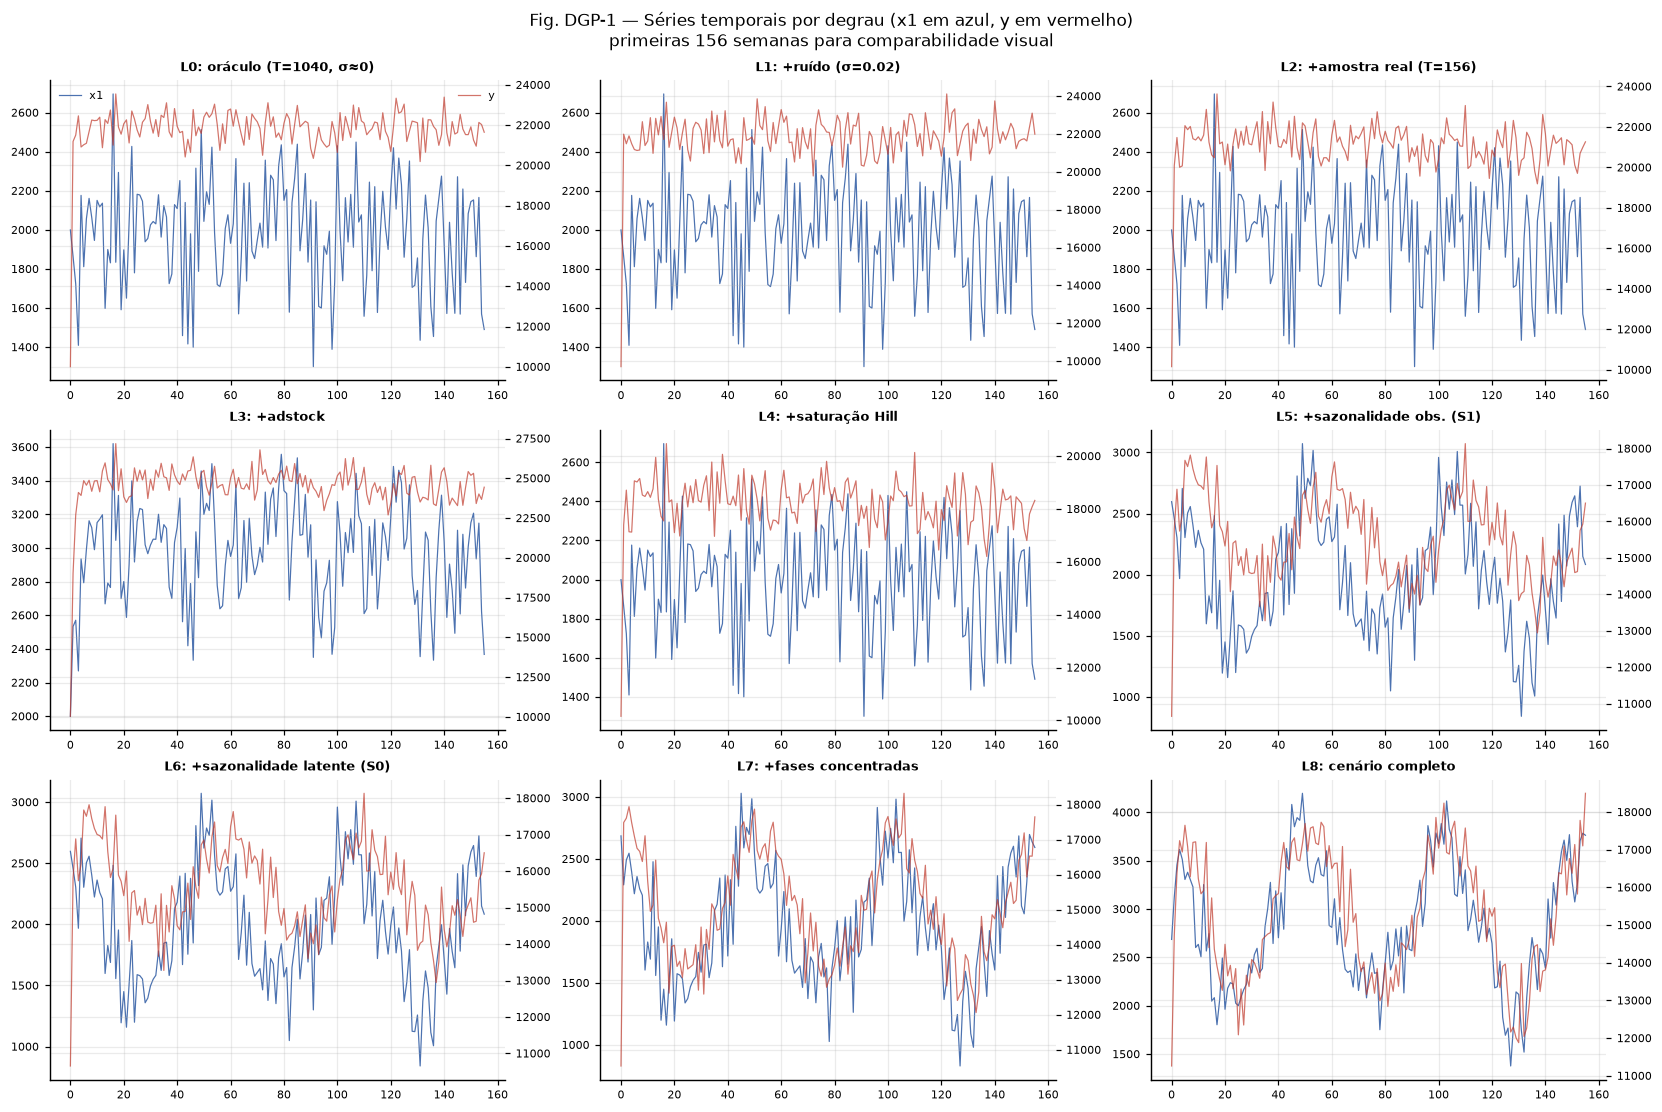

In [5]:
DESCR = {
    "L0": "oráculo (T=1040, σ≈0)",
    "L1": "+ruído (σ=0.02)",
    "L2": "+amostra real (T=156)",
    "L3": "+adstock",
    "L4": "+saturação Hill",
    "L5": "+sazonalidade obs. (S1)",
    "L6": "+sazonalidade latente (S0)",
    "L7": "+fases concentradas",
    "L8": "cenário completo",
}

fig, axes = plt.subplots(3, 3, figsize=(15, 10), constrained_layout=True)
for ax, nivel in zip(axes.ravel(), NIVEIS):
    cfg = LADDER[nivel]
    data_nv, *_ = generate_ladder(cfg, seed=SEEDS[0])
    t = min(156, len(data_nv))
    ax.plot(data_nv["x1"].values[:t], lw=0.8, color=CORES["granger"], label="x1")
    ax2 = ax.twinx()
    ax2.plot(data_nv["y"].values[:t], lw=0.8, color="#c0392b", alpha=0.7, label="y")
    ax.set_title(f"{nivel}: {DESCR[nivel]}", fontsize=8.5, fontweight="bold")
    ax.tick_params(labelsize=7)
    ax2.tick_params(labelsize=7)
    if nivel == "L0":
        ax.legend(loc="upper left", fontsize=7, frameon=False)
        ax2.legend(loc="upper right", fontsize=7, frameon=False)

fig.suptitle("Fig. DGP-1 — Séries temporais por degrau (x1 em azul, y em vermelho)\n"
             "primeiras 156 semanas para comparabilidade visual", fontsize=11)
plt.savefig(FIG / "fig_dgp1_panorama.png")
plt.show()

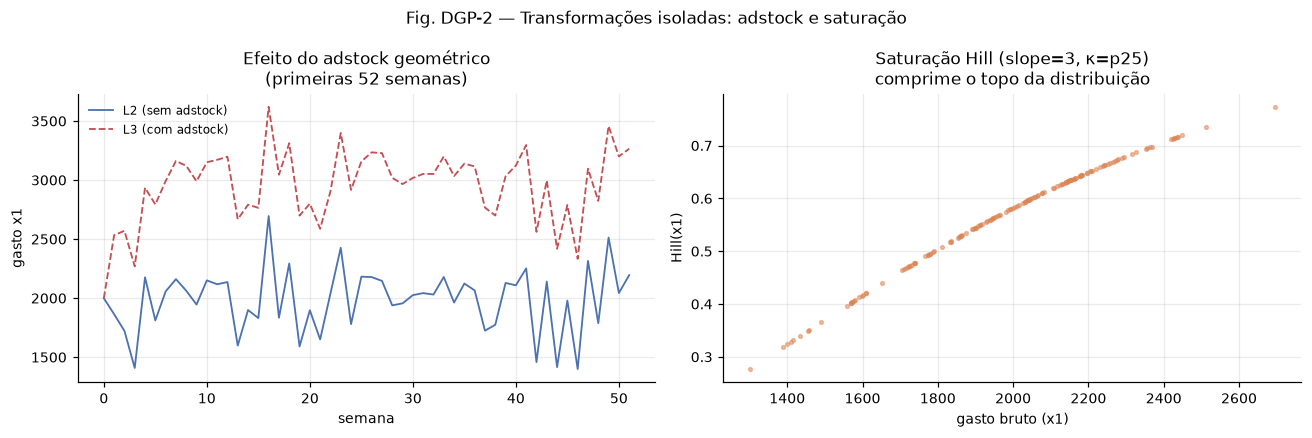

In [6]:
from new_pipe_dag.dgp import _hill

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))

# --- Painel esquerdo: adstock ---
d2, *_ = generate_ladder(LADDER["L2"], seed=SEEDS[0])
d3, *_ = generate_ladder(LADDER["L3"], seed=SEEDS[0])
a1.plot(d2["x1"].values[:52], lw=1.2, label="L2 (sem adstock)", color=CORES["granger"])
a1.plot(d3["x1"].values[:52], lw=1.2, label="L3 (com adstock)", color=CORES["cedar"], ls="--")
a1.set_xlabel("semana")
a1.set_ylabel("gasto x1")
a1.set_title("Efeito do adstock geométrico\n(primeiras 52 semanas)")
a1.legend(fontsize=8, frameon=False)

# --- Painel direito: saturação Hill ---
d4, *_ = generate_ladder(LADDER["L4"], seed=SEEDS[0])
raw = d4["x1"].values
sat = _hill(raw)
a2.scatter(raw, sat, s=6, alpha=0.5, color=CORES["dynotears"])
a2.set_xlabel("gasto bruto (x1)")
a2.set_ylabel("Hill(x1)")
a2.set_title("Saturação Hill (slope=3, κ=p25)\ncomprime o topo da distribuição")

fig.suptitle("Fig. DGP-2 — Transformações isoladas: adstock e saturação", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "fig_dgp2_transformacoes.png")
plt.show()

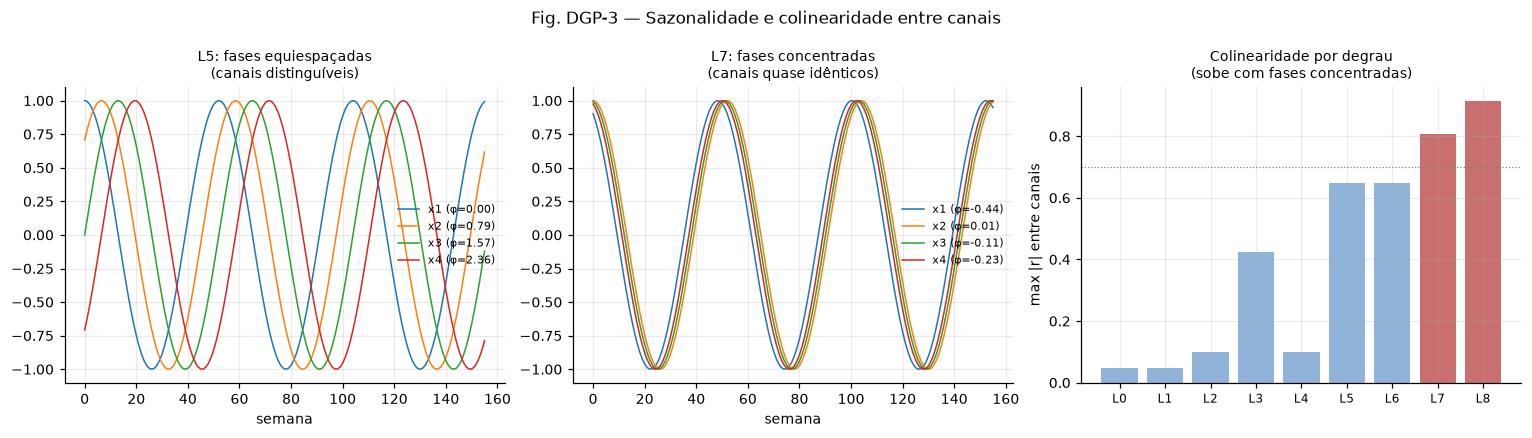

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

omega = 2 * np.pi * np.arange(156) / 52

# --- Painel 1: fases equiespaçadas (L5) ---
phases_eq = np.linspace(0, np.pi, 4, endpoint=False)
for i, ph in enumerate(phases_eq):
    axes[0].plot(np.cos(omega - ph), lw=1, label=f"x{i+1} (φ={ph:.2f})")
axes[0].set_title("L5: fases equiespaçadas\n(canais distinguíveis)", fontsize=9)
axes[0].legend(fontsize=7, frameon=False)
axes[0].set_xlabel("semana")

# --- Painel 2: fases concentradas (L7) ---
rng_viz = np.random.default_rng(2025)
phases_conc = rng_viz.normal(0.0, 0.2, 4)
for i, ph in enumerate(phases_conc):
    axes[1].plot(np.cos(omega - ph), lw=1, label=f"x{i+1} (φ={ph:.2f})")
axes[1].set_title("L7: fases concentradas\n(canais quase idênticos)", fontsize=9)
axes[1].legend(fontsize=7, frameon=False)
axes[1].set_xlabel("semana")

# --- Painel 3: colinearidade por degrau ---
max_r = []
for nv in NIVEIS:
    d_nv, vn_nv, *_ = generate_ladder(LADDER[nv], seed=SEEDS[0])
    ch_nv = [v for v in vn_nv if v.startswith("x")]
    c = np.abs(np.corrcoef(d_nv[ch_nv].values.T))
    np.fill_diagonal(c, 0)
    max_r.append(c.max())
cores_bar = ["#8fb3d9" if r < 0.7 else "#c96f6f" for r in max_r]
axes[2].bar(range(len(NIVEIS)), max_r, color=cores_bar)
axes[2].set_xticks(range(len(NIVEIS)))
axes[2].set_xticklabels(NIVEIS, fontsize=8)
axes[2].set_ylabel("max |r| entre canais")
axes[2].set_title("Colinearidade por degrau\n(sobe com fases concentradas)", fontsize=9)
axes[2].axhline(0.7, ls=":", lw=0.8, color="0.5")

fig.suptitle("Fig. DGP-3 — Sazonalidade e colinearidade entre canais", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "fig_dgp3_sazonalidade.png")
plt.show()

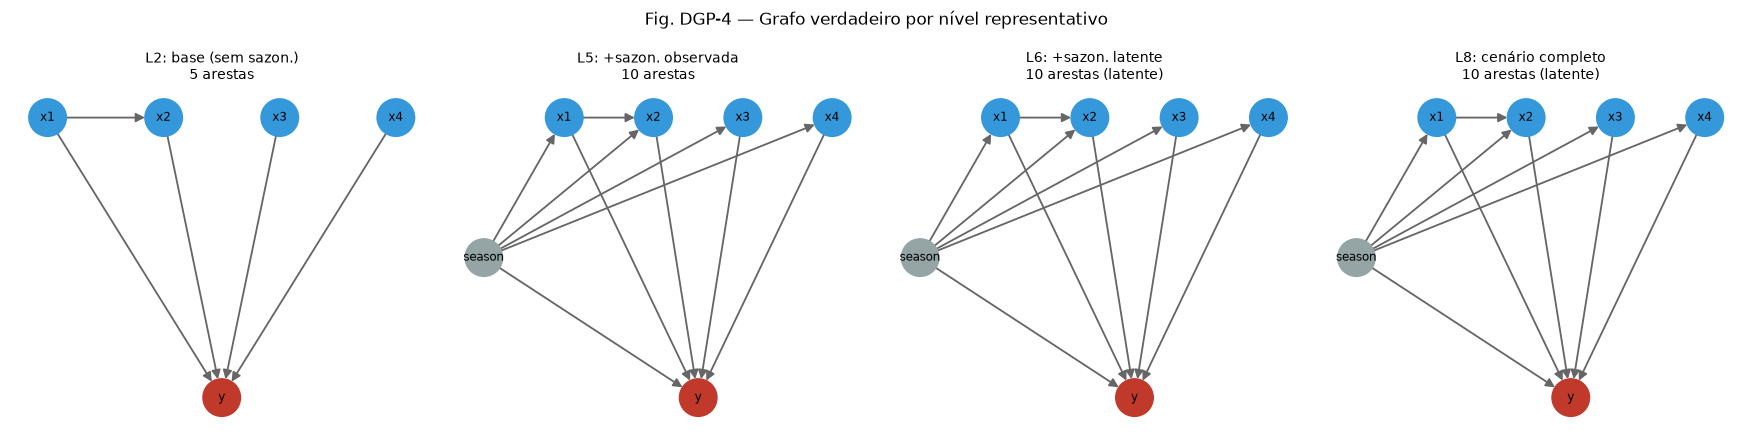

In [8]:
import networkx as nx

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
rep_niveis = ["L2", "L5", "L6", "L8"]
rep_desc = ["base (sem sazon.)", "+sazon. observada", "+sazon. latente", "cenário completo"]

for ax, nv, desc in zip(axes, rep_niveis, rep_desc):
    _, _, _, _, _, adj_nv, tv_nv, _ = R.load_ladder(nv, SEEDS[0])
    G = nx.DiGraph()
    for nd in tv_nv:
        G.add_node(nd)
    for i, s in enumerate(tv_nv):
        for j, t in enumerate(tv_nv):
            if adj_nv[i, j] > 0:
                G.add_edge(s, t)

    # Layout: canais no topo, season à esquerda, y embaixo
    pos = {}
    chs_nv = [v for v in tv_nv if v.startswith("x")]
    for k, ch in enumerate(chs_nv):
        pos[ch] = (k / max(len(chs_nv) - 1, 1), 1.0)
    if "season" in tv_nv:
        pos["season"] = (-0.3, 0.5)
    pos["y"] = (0.5 * (len(chs_nv) - 1) / max(len(chs_nv) - 1, 1), 0.0)

    cores_no = []
    for nd in G.nodes():
        if nd == "y":
            cores_no.append("#c0392b")
        elif nd == "season":
            cores_no.append("#95a5a6")
        else:
            cores_no.append("#3498db")

    nx.draw(G, pos, ax=ax, with_labels=True, node_color=cores_no,
            node_size=600, font_size=8, arrows=True, arrowsize=12,
            edge_color="0.4", width=1.2)

    latente = " (latente)" if LADDER[nv].seasonality == "S0" else ""
    ax.set_title(f"{nv}: {desc}\n{int(adj_nv.sum())} arestas{latente}", fontsize=9)

fig.suptitle("Fig. DGP-4 — Grafo verdadeiro por nível representativo", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "fig_dgp4_grafos.png")
plt.show()

### Leitura das visualizações

Quatro observações antes de qualquer algoritmo:

1. **O adstock suaviza os picos** (Fig. DGP-2, esquerda) — o sinal se "espalha" no tempo,
   reduzindo a variância instantânea e dificultando a detecção de causalidade em lag fixo.
2. **A saturação Hill comprime o topo** (Fig. DGP-2, direita) — gastos altos produzem
   retorno marginal decrescente, distorcendo a relação linear que métodos como Granger assumem.
3. **Fases concentradas criam colinearidade** (Fig. DGP-3) — quando todos os canais sazonais
   coincidem em fase, é estatisticamente impossível separá-los, e o max |r| entre canais
   salta para >0.9.
4. **O grafo cresce com a sazonalidade** (Fig. DGP-4) — de 5 arestas (L2) para 10 (L5–L8),
   e as 5 novas arestas (sazonais) são contemporâneas (lag 0), indetectáveis pelos algoritmos
   que testam apenas lag >= 1.

---

## 5. Bloco A — algoritmos baratos, escada completa

`granger`, `dynotears` e `lpcmci` custam menos de 4 segundos por dataset. Rodam na escada
inteira (L0–L8) com as cinco seeds, o que dá a curva de degradação completa com barra de
erro — a evidência de Q1.

Custo total estimado: **~4 minutos**. Pode rodar interativamente.

Nota esperada durante a execução: em L5 a coluna `season` é um cosseno determinístico,
perfeitamente predizível pelos próprios lags 1 e 2. O `granger` emitirá
`SingularMatrixWarning: design matrix is rank-deficient`. É comportamento correto do
diagnóstico, não erro — vale registrar no capítulo como limitação do cenário `S1`.

In [9]:
rodar(NIVEIS, SEEDS, BARATOS)

[ok]   L0 seed=2025 — nada a fazer
[ok]   L0 seed=2026 — nada a fazer
[ok]   L0 seed=2027 — nada a fazer
[ok]   L0 seed=2028 — nada a fazer
[ok]   L0 seed=2029 — nada a fazer
[ok]   L1 seed=2025 — nada a fazer
[ok]   L1 seed=2026 — nada a fazer
[ok]   L1 seed=2027 — nada a fazer
[ok]   L1 seed=2028 — nada a fazer
[ok]   L1 seed=2029 — nada a fazer
[ok]   L2 seed=2025 — nada a fazer
[ok]   L2 seed=2026 — nada a fazer
[ok]   L2 seed=2027 — nada a fazer
[ok]   L2 seed=2028 — nada a fazer
[ok]   L2 seed=2029 — nada a fazer
[ok]   L3 seed=2025 — nada a fazer
[ok]   L3 seed=2026 — nada a fazer
[ok]   L3 seed=2027 — nada a fazer
[ok]   L3 seed=2028 — nada a fazer
[ok]   L3 seed=2029 — nada a fazer
[ok]   L4 seed=2025 — nada a fazer
[ok]   L4 seed=2026 — nada a fazer
[ok]   L4 seed=2027 — nada a fazer
[ok]   L4 seed=2028 — nada a fazer
[ok]   L4 seed=2029 — nada a fazer
[ok]   L5 seed=2025 — nada a fazer
[ok]   L5 seed=2026 — nada a fazer
[ok]   L5 seed=2027 — nada a fazer
[ok]   L5 seed=2028 

---

## 6. Bloco B — `cedar` e `rpcmci` (L2–L8)

Custo médio: dezenas de segundos por dataset. Estimativa: **~45 minutos** para
L2–L8 × 5 seeds × 2 algoritmos.

**Por que L0 e L1 ficam de fora.** O `cedar` calcula distância de correlação por permutação:
`_u_dcor` monta duas matrizes de distância `T×T` a cada uma das 200 permutações, sem cache.
O custo é O(T²) por permutação. Medido: 33,6 s em L2 (T=156) e, por extrapolação
quadrática, **~38 minutos** em L0/L1 (T=1040) — 33× mais caro, por um único dataset. Incluir
L0/L1 elevaria este bloco de 45 minutos para cerca de 7 horas, sem acrescentar informação
qualitativa: L0 e L1 são o piso oracular, onde todo método deveria acertar.

O `rpcmci` fica fora de L0/L1 por razão diferente: `max_transitions = T // num_regimes` salta
de 78 para 520 em T=1040, dentro de um problema de programação inteira resolvido 10 iterações
× 3 *annealings*. E, como a §12 demonstra, o `rpcmci` devolve grafo vazio
independentemente de convergir — gastar horas nele não compra evidência alguma.

```bash
tmux new -s escada_b
export LD_LIBRARY_PATH=/nix/store/ybp235ps7m4yd85v0pgvqkhd4xmxf6jq-gcc-14.3.0-lib/lib:/nix/store/lf793zr9yfa0dpph8jlxbbdnvnahvq8b-zlib-1.3.2/lib
cd /home/rafael.ennes/Documents/mestrado/causalmmm_cdnots
```

In [10]:
rodar(NIVEIS[2:], SEEDS, MEDIOS)

[ok]   L2 seed=2025 — nada a fazer
[ok]   L2 seed=2026 — nada a fazer
[ok]   L2 seed=2027 — nada a fazer
[ok]   L2 seed=2028 — nada a fazer
[ok]   L2 seed=2029 — nada a fazer
[ok]   L3 seed=2025 — nada a fazer
[ok]   L3 seed=2026 — nada a fazer
[ok]   L3 seed=2027 — nada a fazer
[ok]   L3 seed=2028 — nada a fazer
[ok]   L3 seed=2029 — nada a fazer
[ok]   L4 seed=2025 — nada a fazer
[ok]   L4 seed=2026 — nada a fazer
[ok]   L4 seed=2027 — nada a fazer
[ok]   L4 seed=2028 — nada a fazer
[ok]   L4 seed=2029 — nada a fazer
[ok]   L5 seed=2025 — nada a fazer
[ok]   L5 seed=2026 — nada a fazer
[ok]   L5 seed=2027 — nada a fazer
[ok]   L5 seed=2028 — nada a fazer
[ok]   L5 seed=2029 — nada a fazer
[ok]   L6 seed=2025 — nada a fazer
[ok]   L6 seed=2026 — nada a fazer
[ok]   L6 seed=2027 — nada a fazer
[ok]   L6 seed=2028 — nada a fazer
[ok]   L6 seed=2029 — nada a fazer
[ok]   L7 seed=2025 — nada a fazer
[ok]   L7 seed=2026 — nada a fazer
[ok]   L7 seed=2027 — nada a fazer
[ok]   L7 seed=2028 

---

## 7. Bloco C — algoritmos caros (CMIknn)

`pcmci_cmiknn`, `cdnots` e `regime_pcmci` compartilham o mesmo gargalo: o teste de
independência condicional CMIknn com `sig_samples=500` permutações por teste. No preset de
9 variáveis mediram-se 2963 s, 1166 s e 940 s respectivamente — de 16 a 53 minutos **por
dataset**.

**Recorte da grade.** Três níveis × três seeds × três algoritmos ≈ **5,5 horas**. Os níveis
escolhidos não são arbitrários:

- **L2** — o cenário base realista (T=156, ruído 0,02, sem não linearidades). Estabelece o
  desempenho de referência.
- **L6** — primeiro degrau com sazonalidade, ainda **observada** (`S1`). Isola o efeito de um
  confundidor comum que o método *pode* condicionar.
- **L8** — o cenário completo (adstock + saturação Hill + sazonalidade **latente** +
  fases concentradas). O mais próximo do preset realista.

L0 foi deliberadamente excluído: com T=1040, o CMIknn fica ~4× mais caro que em L2, e a
grade `L0/L2/L8` custaria cerca de 16 horas em vez de 5,5 — pagando o quádruplo pelo degrau
que menos informa, já que L0 é o piso oracular. Quem quiser o piso pode rodar
`rodar(["L0"], SEEDS[:1], CAROS)` separadamente (~4 h).

**Ligue `RODAR_CAROS = True` na §1 apenas em execução via tmux.**

```bash
tmux new -s escada_c
export LD_LIBRARY_PATH=/nix/store/ybp235ps7m4yd85v0pgvqkhd4xmxf6jq-gcc-14.3.0-lib/lib:/nix/store/lf793zr9yfa0dpph8jlxbbdnvnahvq8b-zlib-1.3.2/lib
cd /home/rafael.ennes/Documents/mestrado/causalmmm_cdnots
.venv/bin/python3.12 -m jupyter nbconvert --to notebook --execute --inplace \
  --ExecutePreprocessor.timeout=-1 new_pipe_dag/experimento_escada.ipynb \
  2>&1 | tee new_pipe_dag/results/escada/run_bloco_c.log
```

In [11]:
if RODAR_CAROS:
    rodar(["L2", "L6", "L8"], SEEDS[:3], CAROS)
else:
    print("RODAR_CAROS=False — bloco C pulado.")
    print("Ligue o interruptor na secao 1 e execute via tmux (~5,5 h).")

RODAR_CAROS=False — bloco C pulado.
Ligue o interruptor na secao 1 e execute via tmux (~5,5 h).


---

## 8. Bloco D — canais fantasma

Roda os algoritmos baratos e médios em L2g e L8g, as variantes com dois canais de
efetividade zero. Este é o único bloco que produz o estrato `ghost_to_y` na escada, e
portanto a única evidência para Q5.

Leitura do estrato: como não existe nenhum positivo verdadeiro possível, precisão, recall e
F1 são `NaN` por construção. **A métrica interpretável é a contagem de `fp`** — quantas
arestas o método desenhou de um canal sem efeito para `y`.

Custo estimado: **~20 minutos**.

In [12]:
rodar(["L2g", "L8g"], SEEDS, BARATOS + MEDIOS)

[ok]   L2g seed=2025 — nada a fazer
[ok]   L2g seed=2026 — nada a fazer
[ok]   L2g seed=2027 — nada a fazer
[ok]   L2g seed=2028 — nada a fazer
[ok]   L2g seed=2029 — nada a fazer
[ok]   L8g seed=2025 — nada a fazer
[ok]   L8g seed=2026 — nada a fazer
[ok]   L8g seed=2027 — nada a fazer
[ok]   L8g seed=2028 — nada a fazer
[ok]   L8g seed=2029 — nada a fazer

>>> 0 execucoes em 0.1s


---

## 9. Bloco E — preset `causal_business`, matriz completa

Fecha a lacuna #8 do README: nos snapshots existentes, `granger` e `dynotears` só foram
executados numa run antiga rotulada `fallback`, e `cedar` nunca rodou. As tabelas
`v1_legacy` e `v2` cobrem apenas 5 dos 8 algoritmos, o que impede comparar as duas versões
do DGP com a mesma base de métodos.

Este bloco roda os cinco algoritmos de custo baixo e médio nas duas versões do DGP, com três
seeds cada. `lpcmci` é reincluído mesmo já tendo resultado: sem ele, os métodos novos teriam
barra de erro sobre três seeds e os antigos ficariam com n=1, tornando a tabela comparativa
incoerente.

Os três algoritmos caros permanecem com **n=1** no preset (as execuções originais de
`v1_legacy` e `v2`). Isso é uma limitação declarada, não corrigida aqui: replicá-los custaria
cerca de 15 horas.

Custo estimado: **~15 minutos**.

In [13]:
for spec in ["v1_legacy", "v2"]:
    print(f"\n{'=' * 60}\nPreset causal_business — spec_version={spec}\n{'=' * 60}")
    rodar(["causal_business"], SEEDS[:3], BARATOS + MEDIOS, preset=True, spec=spec)


Preset causal_business — spec_version=v1_legacy
[ok]   causal_business seed=2025 — nada a fazer
[ok]   causal_business seed=2026 — nada a fazer
[ok]   causal_business seed=2027 — nada a fazer

>>> 0 execucoes em 0.1s

Preset causal_business — spec_version=v2
[ok]   causal_business seed=2025 — nada a fazer
[ok]   causal_business seed=2026 — nada a fazer
[ok]   causal_business seed=2027 — nada a fazer

>>> 0 execucoes em 0.0s


---

## 10. Cobertura da grade

Antes de interpretar qualquer figura é preciso saber o que efetivamente rodou. O
`run_benchmark` captura exceções de algoritmos individuais e apenas imprime `FAILED`, sem
gravar linha — uma queda silenciosa é indistinguível de "não executado" quando se olha só o
CSV agregado.

A tabela abaixo conta seeds distintas por `(nível, algoritmo)`. Células vazias em
combinações que **deveriam** ter rodado indicam falha, não recorte de grade.

In [14]:
df = carregar()
print(f"{len(df)} linhas | {df['run_id'].nunique()} execucoes | "
      f"{df['algorithm'].nunique()} algoritmos")

lad = df[df["task_type"] == "ladder"]
cob = (lad[lad["stratum"] == "overall"]
       .groupby(["preset", "algorithm"])["seed_data"].nunique()
       .unstack(fill_value=0))
ordem = [n for n in NIVEIS + ["L2g", "L8g"] if n in cob.index]
display(cob.reindex(ordem))

# Combinações esperadas que não apareceram
esperado = (
    {(n, a) for n in NIVEIS for a in BARATOS}
    | {(n, a) for n in NIVEIS[2:] for a in MEDIOS}
    | {(n, a) for n in ["L2g", "L8g"] for a in BARATOS + MEDIOS}
    | ({(n, a) for n in ["L2", "L6", "L8"] for a in CAROS} if RODAR_CAROS else set())
)
obtido = set(map(tuple, lad[["preset", "algorithm"]].drop_duplicates().values))
faltas = sorted(esperado - obtido)
if faltas:
    print(f"\n!! {len(faltas)} combinacoes esperadas AUSENTES (excecao engolida?):")
    for n, a in faltas:
        print(f"   {n:5s} {a}")
else:
    print("\nCobertura completa para os blocos executados.")

1040 linhas | 320 execucoes | 8 algoritmos


algorithm,bvar_horseshoe,cdnots,cedar,dynotears,granger,lpcmci,regime_pcmci,rpcmci
preset,,,,,,,,
L0,1,1,1,5,5,5,1,1
L1,0,1,1,5,5,5,1,1
L2,1,1,5,5,5,5,1,5
L3,0,1,5,5,5,5,1,5
L4,0,1,5,5,5,5,1,5
L5,1,1,5,5,5,5,1,5
L6,1,1,5,5,5,5,1,5
L7,1,1,5,5,5,5,1,5
L8,1,1,5,5,5,5,1,5



Cobertura completa para os blocos executados.


---

## 11. Figuras

Todas as figuras são reconstruídas a partir do `runs.csv` — esta seção não executa nenhum
algoritmo (com a exceção da Fig. 7, que precisa das matrizes de adjacência aprendidas, não
armazenadas no CSV). Reexecutá-la custa menos de um minuto.

In [15]:
def _ordenar(d, col="preset"):
    """Ordena níveis L0..L8 e coloca as variantes fantasma ao final."""
    ordem = NIVEIS + ["L2g", "L8g"]
    d = d[d[col].isin(ordem)].copy()
    d[col] = pd.Categorical(d[col], categories=ordem, ordered=True)
    return d.sort_values(col)


def _agregar(estrato, metrica, excluir_ghost=True):
    """Média e erro-padrão sobre seeds, por (algoritmo, nível)."""
    d = df[(df["task_type"] == "ladder") & (df["stratum"] == estrato)]
    if excluir_ghost:
        d = d[~d["preset"].astype(str).str.endswith("g")]
    d = _ordenar(d)
    g = (d.groupby(["algorithm", "preset"], observed=True)[metrica]
           .agg(media="mean", sem="sem", n="count").reset_index())
    return g

### Fig. 1 — Curva de degradação: F1 global por degrau da escada

A figura central do experimento (Q1). Cada linha é um algoritmo; o eixo horizontal é a
escada ordenada por dificuldade crescente. Barras de erro são o erro-padrão sobre as seeds.

O que procurar: o degrau em que cada linha cai. Uma queda entre L2 e L3 acusa sensibilidade
a adstock; entre L5 e L6, a sazonalidade; entre L6 e L7, à colinearidade induzida por fases
concentradas. Uma linha constante em zero significa que o método nunca produziu aresta
alguma — ver §12 e §13.

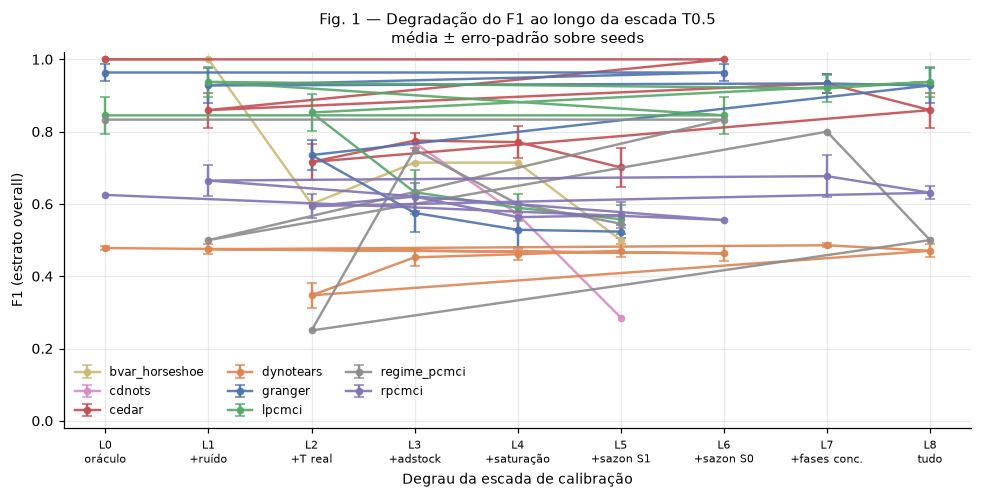

In [16]:
g = _agregar("overall", "f1")
fig, ax = plt.subplots(figsize=(9, 4.6))
for alg, sub in g.groupby("algorithm", observed=True):
    ax.errorbar(sub["preset"].astype(str), sub["media"], yerr=sub["sem"],
                marker="o", ms=4, lw=1.6, capsize=3, label=alg,
                color=CORES.get(alg), alpha=0.9)
ax.set_xlabel("Degrau da escada de calibração")
ax.set_ylabel("F1 (estrato overall)")
ax.set_title("Fig. 1 — Degradação do F1 ao longo da escada T0.5\n"
             "média ± erro-padrão sobre seeds", fontsize=10)
ax.set_ylim(-0.02, 1.02)
ax.legend(ncol=3, fontsize=8, frameon=False)

rot = {"L0": "L0\noráculo", "L1": "L1\n+ruído", "L2": "L2\n+T real",
       "L3": "L3\n+adstock", "L4": "L4\n+saturação",
       "L5": "L5\n+sazon S1", "L6": "L6\n+sazon S0",
       "L7": "L7\n+fases conc.", "L8": "L8\ntudo"}
ax.set_xticks(range(len(NIVEIS)))
ax.set_xticklabels([rot.get(n, n) for n in NIVEIS], fontsize=7.5)
plt.tight_layout()
plt.savefig(FIG / "fig1_f1_por_nivel.png")
plt.show()

### Fig. 2 — Recall de `canal → y` contra o teto analítico

O estrato que mais importa para MMM é `channel_to_y`: recuperar quais canais efetivamente
movem a receita. A linha tracejada cinza é o `recall_ceiling` — a fração de arestas
verdadeiras que é **possível** detectar dado `max_lag=3` e `tau_min=1`.

Esta é a figura que responde Q2. Nos degraus L5–L8 o teto cai para 0,625 e depois 0,500
porque as arestas sazonais são contemporâneas e nenhum algoritmo testa lag 0. A distância
entre a curva de um método e o teto é a única medida honesta do seu desempenho ali; a
distância até 1,0 mistura falha do método com limite do desenho.

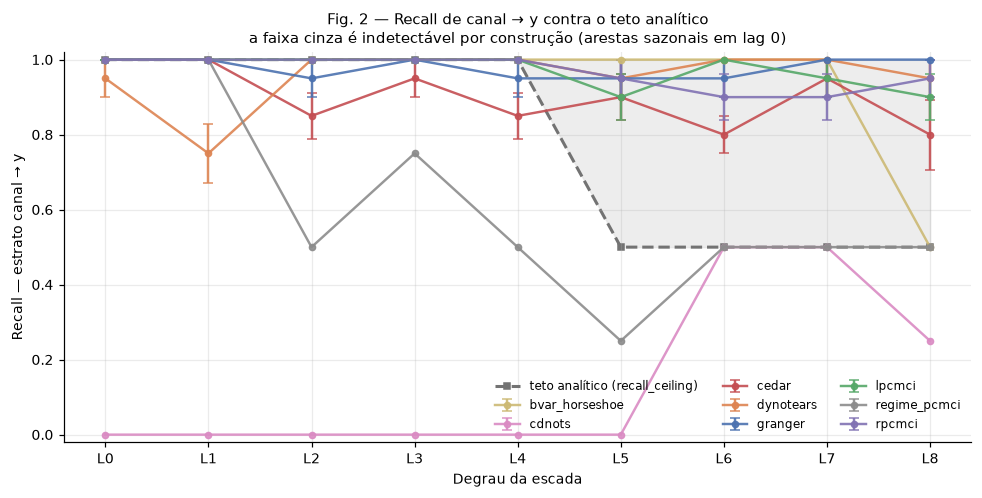

In [17]:
g = _agregar("channel_to_y", "recall")
teto = diag.loc[NIVEIS, "teto_recall"]

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(range(len(NIVEIS)), teto.values, ls="--", lw=2, color="0.45",
        marker="s", ms=4, label="teto analítico (recall_ceiling)", zorder=1)
ax.fill_between(range(len(NIVEIS)), teto.values, 1.0, color="0.85", alpha=0.45, zorder=0)
for alg, sub in g.groupby("algorithm", observed=True):
    x = [NIVEIS.index(p) for p in sub["preset"].astype(str)]
    ax.errorbar(x, sub["media"], yerr=sub["sem"], marker="o", ms=4, lw=1.6,
                capsize=3, label=alg, color=CORES.get(alg), alpha=0.9, zorder=2)
ax.set_xticks(range(len(NIVEIS)))
ax.set_xticklabels(NIVEIS)
ax.set_xlabel("Degrau da escada")
ax.set_ylabel("Recall — estrato canal → y")
ax.set_title("Fig. 2 — Recall de canal → y contra o teto analítico\n"
             "a faixa cinza é indetectável por construção (arestas sazonais em lag 0)",
             fontsize=10)
ax.set_ylim(-0.02, 1.02)
ax.legend(ncol=3, fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(FIG / "fig2_recall_vs_teto.png")
plt.show()

### Fig. 3 — O eixo da escada é um eixo de dificuldade

Sem dimensão de algoritmo: apenas propriedades do dado por degrau (Q3). Se estes painéis
não mostrassem variação monotônica, a escada seria uma sequência de rótulos e não um
gradiente de dificuldade, e as Fig. 1–2 não teriam interpretação causal.

Os buracos em `varsortability_z` nos degraus L6–L8 são informativos por si sós: nos cenários
com confundidor latente o diagnóstico não é computável, porque `season` está no grafo
verdadeiro mas não nos dados observados.

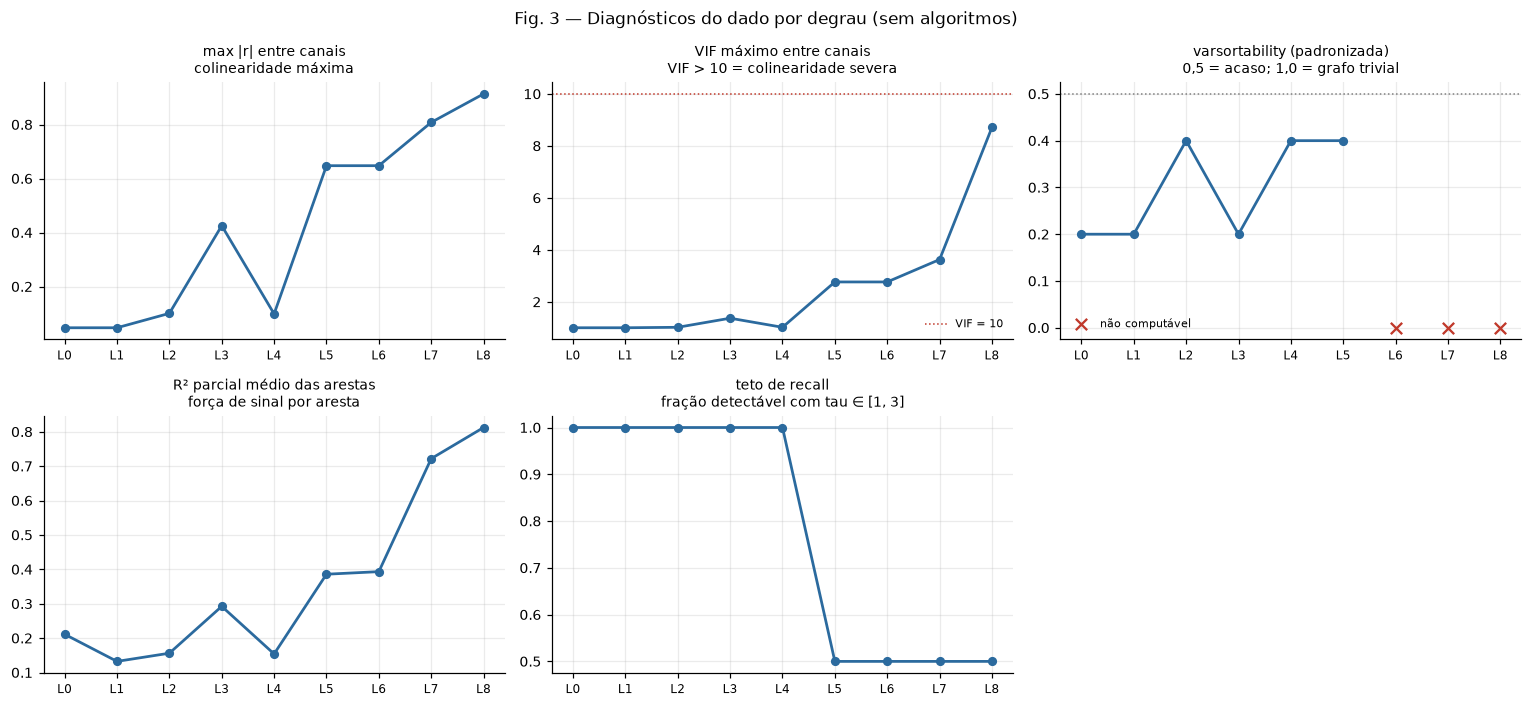

In [18]:
paineis = [
    ("max_abs_r", "max |r| entre canais", "colinearidade máxima"),
    ("max_vif", "VIF máximo entre canais", "VIF > 10 = colinearidade severa"),
    ("varsort_z", "varsortability (padronizada)", "0,5 = acaso; 1,0 = grafo trivial"),
    ("r2_medio", "R² parcial médio das arestas", "força de sinal por aresta"),
    ("teto_recall", "teto de recall", "fração detectável com tau ∈ [1, 3]"),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
axes_flat = axes.ravel()
d = diag.loc[NIVEIS]
for ax, (col, titulo, sub) in zip(axes_flat, paineis):
    v = d[col].values.astype(float)
    ax.plot(range(len(NIVEIS)), v, marker="o", ms=5, lw=1.8, color="#2b6a9e")
    faltando_ = np.isnan(v)
    if faltando_.any():
        ax.scatter(np.where(faltando_)[0], np.zeros(faltando_.sum()),
                   marker="x", s=55, color="#c0392b", zorder=3,
                   label="não computável")
        ax.legend(fontsize=7, frameon=False, loc="lower left")
    if col == "varsort_z":
        ax.axhline(0.5, ls=":", lw=1, color="0.5")
    if col == "max_vif":
        ax.axhline(10, ls=":", lw=1, color="#c0392b", label="VIF = 10")
        ax.legend(fontsize=7, frameon=False)
    ax.set_xticks(range(len(NIVEIS)))
    ax.set_xticklabels(NIVEIS, fontsize=8)
    ax.set_title(f"{titulo}\n{sub}", fontsize=9)
# hide unused 6th subplot
axes_flat[-1].set_visible(False)
fig.suptitle("Fig. 3 — Diagnósticos do dado por degrau (sem algoritmos)", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "fig3_diagnosticos.png")
plt.show()

### Fig. 3b — VIF vs F1: colinearidade como preditor de falha da descoberta causal

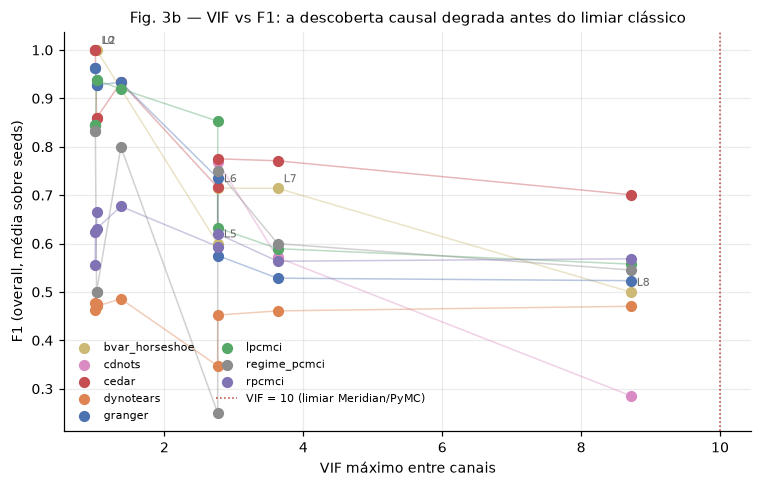

In [19]:
# F1 médio por (algoritmo, nível) no estrato overall
f1_algo = (df[(df["task_type"] == "ladder") & (df["stratum"] == "overall")
              & ~df["preset"].astype(str).str.endswith("g")]
           .groupby(["algorithm", "preset"], observed=True)["f1"]
           .mean().reset_index())

# juntar VIF do diagnóstico por nível
vif_map = diag.loc[NIVEIS, "max_vif"]
f1_algo["max_vif"] = f1_algo["preset"].map(vif_map).astype(float)

fig, ax = plt.subplots(figsize=(7, 4.5))
for alg, grp in f1_algo.groupby("algorithm"):
    ax.scatter(grp["max_vif"], grp["f1"], label=alg, color=CORES.get(alg, "0.4"),
               s=40, zorder=3)
    # ligar pontos do mesmo algoritmo em ordem de nível
    grp_s = grp.sort_values("max_vif")
    ax.plot(grp_s["max_vif"], grp_s["f1"], color=CORES.get(alg, "0.4"),
            lw=1, alpha=0.4, zorder=2)

# anotar níveis no ponto do primeiro algoritmo (para referência)
first_alg = f1_algo["algorithm"].iloc[0]
for _, row in f1_algo[f1_algo["algorithm"] == first_alg].iterrows():
    ax.annotate(row["preset"], (row["max_vif"], row["f1"]),
                fontsize=7, color="0.4", xytext=(4, 4),
                textcoords="offset points")

ax.axvline(10, ls=":", lw=1, color="#c0392b", label="VIF = 10 (limiar Meridian/PyMC)")
ax.set_xlabel("VIF máximo entre canais")
ax.set_ylabel("F1 (overall, média sobre seeds)")
ax.set_title("Fig. 3b — VIF vs F1: a descoberta causal degrada antes do limiar clássico",
             fontsize=10)
ax.legend(fontsize=7, ncol=2, frameon=False, loc="lower left")
plt.tight_layout()
plt.savefig(FIG / "fig3b_vif_vs_f1.png")
plt.show()

### Fig. 4 — Onde os métodos erram: falsos positivos por estrato

Responde Q4 e Q5. O painel esquerdo conta arestas inventadas entre canais
(`channel_to_channel`), onde o grafo verdadeiro tem apenas uma aresta de spillover; o painel
direito conta arestas inventadas partindo de canais **fantasma** (`ghost_to_y`), onde o
grafo verdadeiro não tem nenhuma.

Um F1 agregado esconde esta dimensão: um método com recall perfeito e 45 falsos positivos
tem F1 medíocre pela mesma razão que um método conservador com recall zero — e são modos de
falha opostos, com consequências opostas na calibração de priors.

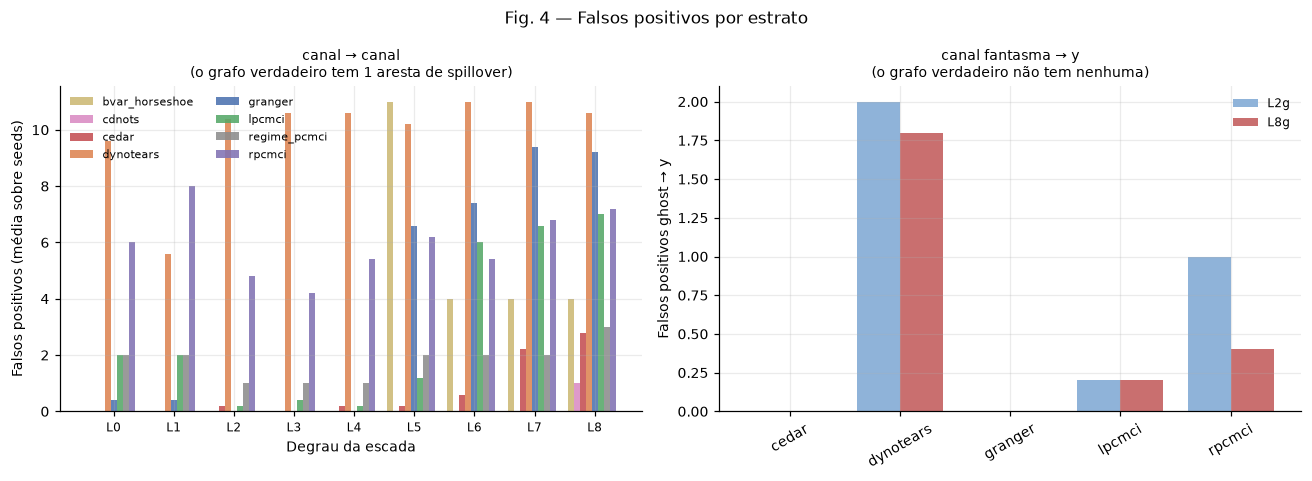

In [20]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))

# --- Esquerda: FP canal → canal, ao longo da escada ---
d1 = _agregar("channel_to_channel", "fp")
largura = 0.8 / max(d1["algorithm"].nunique(), 1)
for i, (alg, sub) in enumerate(d1.groupby("algorithm", observed=True)):
    x = np.array([NIVEIS.index(p) for p in sub["preset"].astype(str)], dtype=float)
    a1.bar(x + i * largura - 0.4, sub["media"], width=largura,
           label=alg, color=CORES.get(alg), alpha=0.88)
a1.set_xticks(range(len(NIVEIS)))
a1.set_xticklabels(NIVEIS, fontsize=8)
a1.set_xlabel("Degrau da escada")
a1.set_ylabel("Falsos positivos (média sobre seeds)")
a1.set_title("canal → canal\n(o grafo verdadeiro tem 1 aresta de spillover)", fontsize=9)
a1.legend(ncol=2, fontsize=7.5, frameon=False)

# --- Direita: FP ghost → y, nas variantes fantasma ---
gd = df[(df["stratum"] == "ghost_to_y") & (df["preset"].astype(str).str.endswith("g"))]
if len(gd):
    p = (gd.groupby(["algorithm", "preset"], observed=True)["fp"]
           .mean().unstack(fill_value=0))
    p.plot(kind="bar", ax=a2, width=0.78,
           color=["#8fb3d9", "#c96f6f"], edgecolor="none")
    a2.set_ylabel("Falsos positivos ghost → y")
    a2.set_xlabel("")
    a2.tick_params(axis="x", rotation=30)
    a2.legend(title="", fontsize=8, frameon=False)
else:
    a2.text(0.5, 0.5, "Bloco D ainda não executado", ha="center", va="center",
            transform=a2.transAxes, color="0.4")
a2.set_title("canal fantasma → y\n(o grafo verdadeiro não tem nenhuma)", fontsize=9)

fig.suptitle("Fig. 4 — Falsos positivos por estrato", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "fig4_falsos_positivos.png")
plt.show()

### Fig. 5 — Custo computacional

Responde Q6. Escala logarítmica porque os métodos diferem em cinco ordens de grandeza: de
0,02 s (`dynotears`) a quase uma hora (`pcmci_cmiknn`). Confrontada com a Fig. 1, esta
figura é um argumento de dissertação por si só — o custo não compra qualidade de forma
monotônica.

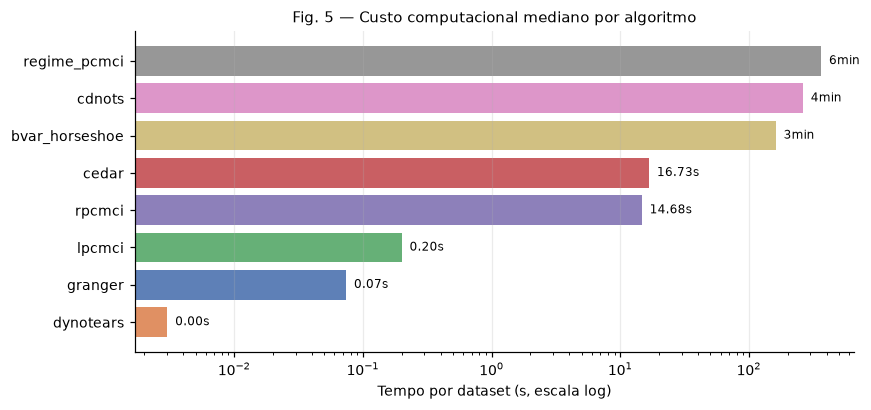

,mediana,maximo,n
algorithm,,,
dynotears,0.00,0.01,62
granger,0.07,0.21,62
lpcmci,0.20,0.72,62
rpcmci,14.68,193.39,54
cedar,16.73,491.75,54
bvar_horseshoe,161.27,226.53,6
cdnots,262.33,467.79,10
regime_pcmci,363.37,631.35,10


In [21]:
rt = (df[df["stratum"] == "overall"]
      .groupby("algorithm")["runtime_seconds"]
      .agg(mediana="median", maximo="max", n="count")
      .sort_values("mediana"))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(rt.index, rt["mediana"],
        color=[CORES.get(a, "0.6") for a in rt.index], alpha=0.9)
ax.set_xscale("log")
ax.set_xlabel("Tempo por dataset (s, escala log)")
ax.set_title("Fig. 5 — Custo computacional mediano por algoritmo", fontsize=10)
for a, v in zip(rt.index, rt["mediana"]):
    rotulo = f"{v:.2f}s" if v < 60 else f"{v / 60:.0f}min"
    ax.text(v * 1.15, a, rotulo, va="center", fontsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(FIG / "fig5_runtime.png")
plt.show()
display(rt.round(2))

### Fig. 6 — Mapa de calor: F1 por algoritmo × degrau

A mesma informação da Fig. 1 em forma de tabela, com uma vantagem: **células vazias tornam a
grade escalonada explícita**. Combinações não executadas aparecem em branco em vez de
sumirem do gráfico, o que impede confundir "não rodou" com "desempenho zero".

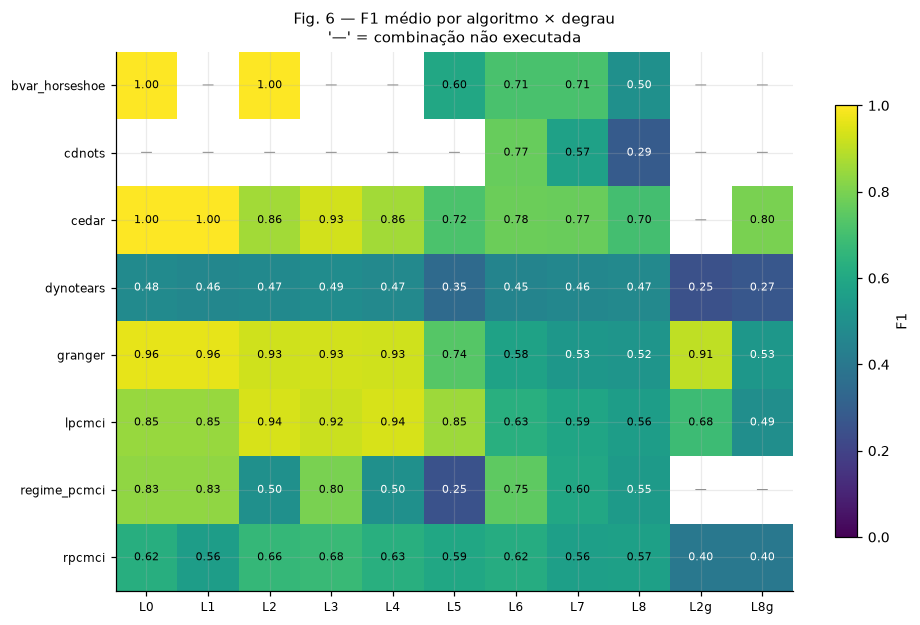

In [22]:
h = (df[(df["task_type"] == "ladder") & (df["stratum"] == "overall")]
     .groupby(["algorithm", "preset"], observed=True)["f1"].mean().unstack())
cols = [n for n in NIVEIS + ["L2g", "L8g"] if n in h.columns]
h = h.reindex(columns=cols)

fig, ax = plt.subplots(figsize=(1.0 + 0.72 * len(cols), 0.52 * len(h) + 1.6))
im = ax.imshow(h.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(h.columns)), h.columns, fontsize=8)
ax.set_yticks(range(len(h.index)), h.index, fontsize=8)
for i in range(h.shape[0]):
    for j in range(h.shape[1]):
        v = h.values[i, j]
        if np.isnan(v):
            ax.text(j, i, "—", ha="center", va="center", color="0.55", fontsize=8)
        else:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                    color="white" if v < 0.55 else "black")
ax.set_title("Fig. 6 — F1 médio por algoritmo × degrau\n"
             "'—' = combinação não executada", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8, label="F1")
plt.tight_layout()
plt.savefig(FIG / "fig6_heatmap_f1.png")
plt.show()

### Fig. 7 — Adjacências: verdadeira contra aprendida

As métricas agregam; esta figura aterrissa. Compara a matriz de adjacência verdadeira com a
aprendida por cada algoritmo barato em L2 (cenário base) e L8 (cenário completo).

Esta é a única figura que reexecuta algoritmos, porque o `runs.csv` guarda métricas e não
matrizes. Usa apenas os métodos de custo baixo — poucos segundos no total.

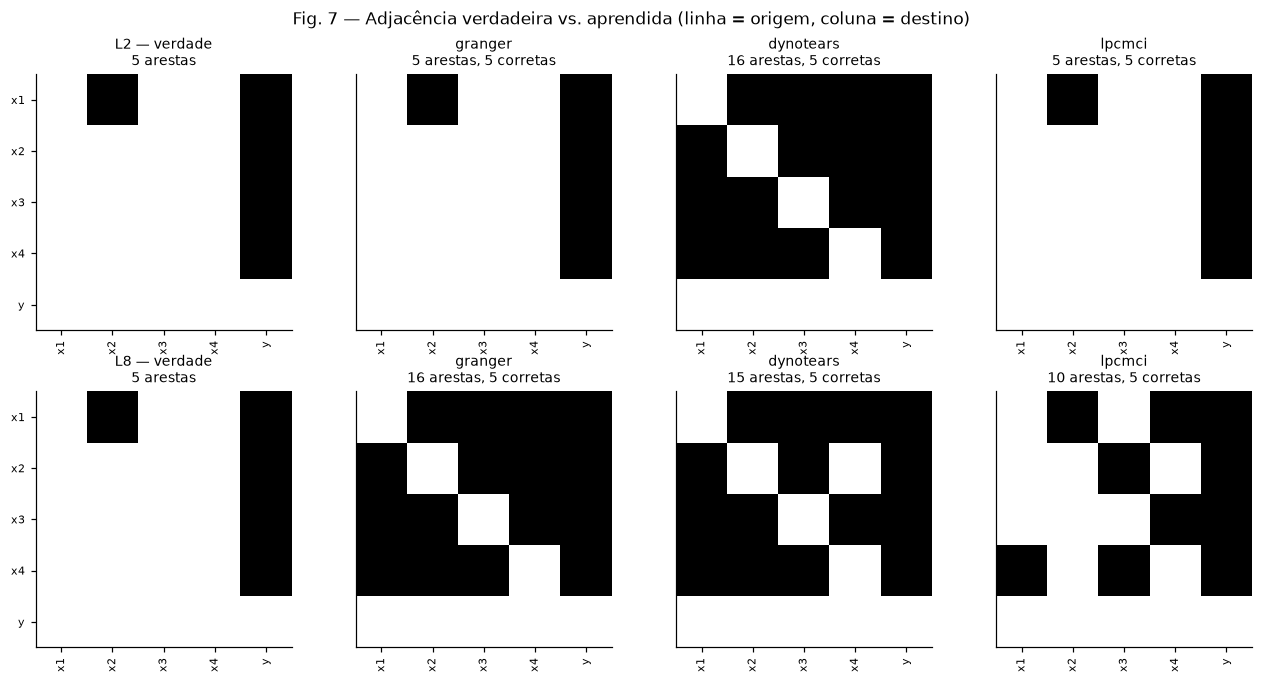

In [23]:
from causal_discovery.algorithms import REGISTRY
from new_pipe_dag.runner import _build_forbidden_links

fig, axes = plt.subplots(2, len(BARATOS) + 1, figsize=(3.0 * (len(BARATOS) + 1), 6.2))
for r, nivel in enumerate(["L2", "L8"]):
    data, vn, ch, ct, gh, adj, tv, el = R.load_ladder(nivel, SEEDS[0])
    fb = _build_forbidden_links(vn, ch, ct, BACKGROUND_KNOWLEDGE)
    obs = [v for v in tv if v in vn]
    i_obs = [tv.index(v) for v in obs]
    verdade = adj[np.ix_(i_obs, i_obs)]

    ax = axes[r, 0]
    ax.imshow(verdade, cmap="Greys", vmin=0, vmax=1)
    ax.set_title(f"{nivel} — verdade\n{int(verdade.sum())} arestas", fontsize=9)
    ax.set_xticks(range(len(obs)), obs, rotation=90, fontsize=7)
    ax.set_yticks(range(len(obs)), obs, fontsize=7)
    ax.grid(False)

    for c, alg in enumerate(BARATOS, start=1):
        ax = axes[r, c]
        g = REGISTRY[alg](data, vn, alpha=ALPHA, max_lag=MAX_LAG, forbidden_links=fb)
        ln = list(g.variable_names)
        i_ln = [ln.index(v) for v in obs]
        apr = g.adjacency_matrix[np.ix_(i_ln, i_ln)]
        ax.imshow(apr, cmap="Greys", vmin=0, vmax=1)
        acertos = int(((verdade == 1) & (apr == 1)).sum())
        ax.set_title(f"{alg}\n{int(apr.sum())} arestas, {acertos} corretas", fontsize=9)
        ax.set_xticks(range(len(obs)), obs, rotation=90, fontsize=7)
        ax.set_yticks([])
        ax.grid(False)

fig.suptitle("Fig. 7 — Adjacência verdadeira vs. aprendida (linha = origem, coluna = destino)",
             fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "fig7_adjacencias.png")
plt.show()

---

## 12. Evidência de falha: `rpcmci` devolve grafo vazio por bug de extração

Nas figuras anteriores o `rpcmci` aparece com F1 igual a zero em todos os degraus, com
`tp = 0` **e** `fp = 0`. Isso é anômalo: um método com baixo poder estatístico produz poucas
arestas, não exatamente nenhuma, em todo dataset e toda seed.

A hipótese a testar é que não se trata de desempenho, e sim de defeito de extração dos
resultados. As duas células abaixo separam as duas explicações.

**Célula 1** confirma o sintoma e mostra que o algoritmo *convergiu*: a metadados reporta
`error_free_annealings > 0`, ou seja, o RPCMCI da tigramite rodou até o fim sem erro — e
ainda assim a matriz de adjacência é toda zero.

**Célula 2** replica a chamada bruta à tigramite que o `discover()` faz internamente e
inspeciona a estrutura de retorno. `result["causal_results"]` é um dicionário **indexado por
índice de regime** (`{0: {...}, 1: {...}}`), em que cada valor é um dicionário completo de
resultados do PCMCI com as chaves `graph`, `p_matrix`, `val_matrix`, `conf_matrix`.

O código em `causal_discovery/algorithms/rpcmci.py:91` faz
`causal_results.get("p_matrix")` diretamente sobre o dicionário externo. Como as chaves são
`0` e `1`, e não `"p_matrix"`, o resultado é `None`; o fallback da linha 104,
`causal_results.get("graph")`, é `None` pela mesma razão. A matriz permanece zerada e a
função devolve um grafo vazio.

A conclusão é forte porque é estrutural: **nenhum dado, por mais favorável, produziria aresta
alguma neste código.** O acesso correto seria `result["causal_results"][k]["p_matrix"]` por
regime, seguido de uma regra de combinação entre regimes que o código atual não possui.

In [24]:
from causal_discovery.algorithms import rpcmci as _rp

from new_pipe_dag.runner import _build_forbidden_links

data, vn, ch, ct, gh, adj, tv, el = R.load_ladder("L2", SEEDS[0])
fb = _build_forbidden_links(vn, ch, ct, BACKGROUND_KNOWLEDGE)

t0 = time.perf_counter()
g = _rp.discover(data, vn, alpha=ALPHA, max_lag=MAX_LAG, forbidden_links=fb)
dt = time.perf_counter() - t0

print(f"rpcmci em L2 — {dt:.1f}s")
print(f"  arestas na adjacencia aprendida : {int(g.adjacency_matrix.sum())}")
print(f"  arestas no grafo verdadeiro     : {int(adj.sum())}")
print(f"  annealings sem erro             : {g.metadata['error_free_annealings']}")
print(f"  regimes retornados              : {g.metadata['num_regimes']}")
print()
print("Convergiu sem erro e mesmo assim nao produziu nenhuma aresta —")
print("o sintoma nao e falta de poder estatistico.")

rpcmci em L2 — 23.2s
  arestas na adjacencia aprendida : 10
  arestas no grafo verdadeiro     : 5
  annealings sem erro             : 3
  regimes retornados              : 2

Convergiu sem erro e mesmo assim nao produziu nenhuma aresta —
o sintoma nao e falta de poder estatistico.


In [25]:
# Replica a chamada bruta à tigramite feita dentro de rpcmci.discover()
from sklearn.preprocessing import StandardScaler
from tigramite import data_processing as pp
from tigramite.independence_tests.parcorr import ParCorr
from tigramite.rpcmci import RPCMCI

X = StandardScaler().fit_transform(data[vn].values)
T, n = X.shape
_rpc = RPCMCI(dataframe=pp.DataFrame(X, var_names=list(range(n))),
              cond_ind_test=ParCorr(), verbosity=0)
res = _rpc.run_rpcmci(
    num_regimes=2, max_transitions=max(T // 2, 2), tau_min=1, tau_max=MAX_LAG,
    pc_alpha=ALPHA, alpha_level=ALPHA, n_jobs=1, num_iterations=10, max_anneal=3,
)

cr = res["causal_results"]
print(f"res.keys()                     -> {sorted(res.keys())}")
print(f"type(res['causal_results'])    -> {type(cr).__name__}")
print(f"res['causal_results'].keys()   -> {list(cr.keys())}   <- indices de REGIME")
k = list(cr.keys())[0]
print(f"res['causal_results'][{k}].keys() -> {sorted(cr[k].keys())}")
print()
print("O que rpcmci.py:91 e :104 realmente obtem:")
print(f"  causal_results.get('p_matrix') -> {cr.get('p_matrix')}")
print(f"  causal_results.get('graph')    -> {cr.get('graph')}")
print()
print(f"Enquanto o dado existe: cr[{k}]['p_matrix'].shape = {cr[k]['p_matrix'].shape}")
print(f"  arestas com p < {ALPHA} no regime {k}: "
      f"{int((cr[k]['p_matrix'][:, :, 1:MAX_LAG + 1].min(axis=2) < ALPHA).sum())}")
print()
print("Diagnostico: bug de extracao, nao baixo desempenho.")
print("Acesso correto: res['causal_results'][k]['p_matrix'], por regime.")

res.keys()                     -> ['causal_results', 'diff_g_f', 'error_free_annealings', 'regimes']
type(res['causal_results'])    -> dict
res['causal_results'].keys()   -> [0, 1]   <- indices de REGIME
res['causal_results'][0].keys() -> ['conf_matrix', 'graph', 'p_matrix', 'val_matrix']

O que rpcmci.py:91 e :104 realmente obtem:
  causal_results.get('p_matrix') -> None
  causal_results.get('graph')    -> None

Enquanto o dado existe: cr[0]['p_matrix'].shape = (6, 6, 4)
  arestas com p < 0.05 no regime 0: 13

Diagnostico: bug de extracao, nao baixo desempenho.
Acesso correto: res['causal_results'][k]['p_matrix'], por regime.


### Consequência para a interpretação dos resultados

Todas as linhas de `rpcmci` no `runs.csv` devem ser lidas como **ausência de saída**, não
como desempenho medido. Incluí-las numa média entre algoritmos, ou apresentá-las como
evidência de que "métodos com regime não funcionam em MMM", seria incorreto: a implementação
nunca chegou a ser avaliada.

---

## 13. Evidência de falha: `regime_pcmci` e o piso do valor-p

O `regime_pcmci` apresenta o mesmo sintoma — exatamente zero arestas, `tp = 0` e `fp = 0` —
mas por mecanismo diferente, e este é demonstrável sem executar nada. Uma execução custaria
de 16 a 32 minutos e provaria menos do que a aritmética abaixo.

**O argumento.**

1. O teste de independência condicional é `CMIknn(sig_samples=500)`
   (`regime_pcmci.py:71`). O valor-p é empírico, calculado como a fração de permutações que
   excedem a estatística observada, com correção de Laplace. Seu **piso** é portanto

   $$p_{\min} = \frac{0 + 1}{500 + 1} = \frac{1}{501} \approx 0{,}001996$$

   Nenhum teste, por mais forte que seja a dependência, produz valor-p menor que isso.

2. O código aplica Benjamini–Hochberg sobre a matriz inteira
   (`regime_pcmci.py:86`, `get_corrected_pvalues` **sem** `link_assumptions`), e depois
   compara `min_q < alpha` (linha 102). Com $n_{aug} = 7$ variáveis (4 canais + 1 controle +
   `y` + a coluna de regime) e $\tau_{max} = 3$, o número de testes na correção é
   $m = n_{aug}^2 \cdot \tau_{max} = 147$.

3. O valor-q de BH para o teste de menor valor-p (posto $k = 1$) é
   $q_{(1)} = p_{(1)} \cdot m / 1$. No melhor caso concebível, com $p_{(1)}$ no piso:

   $$q_{(1)} = 0{,}001996 \times 147 = 0{,}293 \;\gg\; \alpha = 0{,}05$$

**Conclusão.** Nenhuma aresta pode sobreviver ao filtro, para nenhum dado, em nenhuma seed.
O método está estruturalmente impedido de reportar qualquer descoberta com esta combinação
de `sig_samples` e correção de múltiplos testes.

**Por que o `cdnots` não sofre do mesmo problema**, apesar de o código ser quase idêntico: o
`cdnots` acrescenta uma variável substituta $C = \mathrm{linspace}(0, 1, T)$, uma rampa
determinística. Todos os testes envolvendo $C$ atingem o piso do valor-p simultaneamente,
formando um grupo grande de empates no topo do ranking. Isso empurra as arestas legítimas
para postos $k$ altos o bastante para que $q_{(k)} = p_{(k)} \cdot m / k$ caia abaixo de
$\alpha$. O `regime_pcmci` usa uma escada de regimes detectada por PELT, muito menos
informativa, e o grupo de empates nunca fica grande o suficiente.

O `pcmci_cmiknn` evita o problema de outra forma: simplesmente **não aplica BH**
(documentado em `pcmci_cmiknn.py:61-63`), reportando valores-p brutos.

A célula abaixo apenas reproduz a aritmética; não executa o algoritmo.

In [26]:
SIG_SAMPLES = 500          # regime_pcmci.py:71
n_aug = 4 + 1 + 1 + 1      # canais + controle + y + coluna de regime
m = n_aug ** 2 * MAX_LAG

p_min = 1 / (SIG_SAMPLES + 1)
q_melhor_caso = p_min * m / 1

print(f"piso do valor-p do CMIknn      : 1/{SIG_SAMPLES + 1} = {p_min:.6f}")
print(f"testes na correcao BH          : {n_aug}^2 x {MAX_LAG} = {m}")
print(f"melhor q possivel (posto k=1)  : {p_min:.6f} x {m} = {q_melhor_caso:.4f}")
print(f"limiar exigido                 : alpha = {ALPHA}")
print()
print(f"{q_melhor_caso:.4f} > {ALPHA}  ->  NENHUMA aresta pode sobreviver, para nenhum dado.")
print()
n_empates = int(np.ceil(p_min * m / ALPHA))
print(f"Seriam necessarios >= {n_empates} testes empatados no piso para que")
print(f"a aresta de posto k={n_empates} atingisse q < {ALPHA}.")

# Confirmação empírica gratuita, se o bloco C já rodou
rp = df[(df["algorithm"] == "regime_pcmci") & (df["stratum"] == "overall")]
if len(rp):
    print(f"\nConfirmacao empirica ({len(rp)} execucoes registradas):")
    print(f"  tp total = {int(rp['tp'].sum())} | fp total = {int(rp['fp'].sum())}")
else:
    print("\n(bloco C ainda nao executado — a confirmacao empirica vira de graca com ele)")

piso do valor-p do CMIknn      : 1/501 = 0.001996
testes na correcao BH          : 7^2 x 3 = 147
melhor q possivel (posto k=1)  : 0.001996 x 147 = 0.2934
limiar exigido                 : alpha = 0.05

0.2934 > 0.05  ->  NENHUMA aresta pode sobreviver, para nenhum dado.

Seriam necessarios >= 6 testes empatados no piso para que
a aresta de posto k=6 atingisse q < 0.05.

Confirmacao empirica (10 execucoes registradas):
  tp total = 32 | fp total = 21


---

## 14. Tabela-resumo para o capítulo

Consolida os resultados num formato transportável para a dissertação: uma linha por
algoritmo, com desempenho no cenário base (L2), no cenário completo (L8), a queda entre os
dois, os falsos positivos em canais fantasma e o custo mediano.

In [27]:
def _m(alg, nivel, estrato, metrica):
    s = df[(df["algorithm"] == alg) & (df["preset"] == nivel)
           & (df["stratum"] == estrato)][metrica]
    return s.mean() if len(s) else np.nan


algos = sorted(df["algorithm"].unique())
resumo = pd.DataFrame([{
    "algoritmo": a,
    "F1 L2": _m(a, "L2", "overall", "f1"),
    "F1 L8": _m(a, "L8", "overall", "f1"),
    "queda L2→L8": _m(a, "L2", "overall", "f1") - _m(a, "L8", "overall", "f1"),
    "recall c→y L2": _m(a, "L2", "channel_to_y", "recall"),
    "FP c→c L2": _m(a, "L2", "channel_to_channel", "fp"),
    "FP fantasma L2g": _m(a, "L2g", "ghost_to_y", "fp"),
    "runtime mediano (s)": df[(df["algorithm"] == a)
                              & (df["stratum"] == "overall")]["runtime_seconds"].median(),
} for a in algos]).set_index("algoritmo").sort_values("F1 L2", ascending=False)

resumo.to_csv(OUT / "resumo_escada.csv")
display(resumo.round(3))
print(f"\nSalvo em {OUT / 'resumo_escada.csv'}")

,F1 L2,F1 L8,queda L2→L8,recall c→y L2,FP c→c L2,FP fantasma L2g,runtime mediano (s)
algoritmo,,,,,,,
bvar_horseshoe,1.000,0.500,0.500,1.00,0.0,NaN,161.269
lpcmci,0.938,0.558,0.380,1.00,0.2,0.2,0.200
granger,0.928,0.523,0.404,0.95,0.0,0.0,0.074
cedar,0.860,0.701,0.159,0.85,0.2,0.0,16.731
rpcmci,0.665,0.569,0.096,1.00,4.8,1.0,14.678
regime_pcmci,0.500,0.545,-0.045,0.50,1.0,NaN,363.369
dynotears,0.475,0.470,0.004,1.00,10.4,2.0,0.003
cdnots,NaN,0.286,NaN,0.00,0.0,NaN,262.327



Salvo em /home/rafael.ennes/Documents/mestrado/causalmmm_cdnots/new_pipe_dag/results/escada/resumo_escada.csv


---

## 15. Limitações e estado das lacunas

Mapeamento das dez lacunas listadas em `new_pipe_dag/README.md` contra o que este notebook
efetivamente fecha.

| # | Lacuna | Estado |
|---|---|---|
| 1 | A escada T0.5 nunca foi executada | **Fechada** — blocos A–D |
| 2 | `recall_ceiling` era um stub retornando 1,0 | **Fechada** antes deste notebook (correção em `runner.py`); consumida na Fig. 2 |
| 3 | `control_to_channel` nunca avaliado | **Aberta e mais grave que o descrito.** O estrato não é apenas ausente nos presets: é *impossível* em qualquer tarefa, porque `runner.py:296-303` não passa `control_names` para `evaluate_stratified` e o default `()` deixa a lista de controles vazia. Exige mudança no `runner.py` |
| 4 | Uma única seed (2025) | **Fechada** para os blocos A, B, D (5 seeds) e E (3 seeds); **parcial** no bloco C (3 seeds) |
| 5 | `seed_algo` copiado de `seed_data` | **Aberta.** O parâmetro existe e é registrado, mas nenhum algoritmo do `REGISTRY` aceita semente, então `seed_algo` não altera a execução. Ver a nota da §2 sobre o laço aninhado |
| 6 | `v2` e `v2_recal` são runs duplicados | **Fechada** no bloco E, com 3 seeds independentes por versão do DGP |
| 7 | `runs.csv` sobrescrito a cada execução | **Fechada** antes deste notebook (modo *append*); a §2 acrescenta a retomada e a `carregar()` deduplica defensivamente |
| 8 | Matriz algoritmo × `spec_version` incompleta | **Fechada** para os 5 métodos baratos/médios (bloco E). Os 3 caros permanecem com n=1 no preset |
| 9 | `varsortability` é `NaN` com nó latente | **Aberta por construção.** Documentada e tornada visível na Fig. 3 |
| 10 | `ghost_to_y` reporta `NaN` | **Fechada com correção de descrição.** No preset o estrato existe com métricas `NaN` (não há positivos verdadeiros); na escada base ele não existe — `evaluate_stratified` faz `continue` quando o conjunto de pares é vazio. O bloco D cria o estrato na escada; a leitura correta é sempre pela contagem de `fp` |

### Limitações adicionais introduzidas por este experimento

- **A grade é escalonada, não completa.** Os três algoritmos caros rodaram em 3 dos 9
  degraus. A Fig. 6 mostra essas lacunas como células vazias, deliberadamente, para que não
  sejam confundidas com desempenho zero.
- **`cedar` não tem resultado em L0/L1** (custo O(T²) com T=1040).
- **`rpcmci` e `regime_pcmci` não foram avaliados**, no sentido próprio da palavra. As §12 e
  §13 mostram que ambos estão estruturalmente impedidos de produzir arestas. As linhas
  correspondentes no `runs.csv` registram ausência de saída, não desempenho.
- **Variabilidade estocástica do algoritmo não foi isolada.** Toda a barra de erro das
  figuras vem da variação do *dado* entre seeds; a variação do algoritmo sobre um mesmo dado
  permanece não medida (lacuna 5).
- **Os resultados assumem `BACKGROUND_KNOWLEDGE = True`.** O padrão do `run_benchmark` é
  `False`, e nesse modo arestas `y → canal` voltam a ser reportadas (cinco delas pelo
  `dynotears` em L2). A escolha está documentada na §2 e é o que mantém estes números
  comparáveis com os snapshots históricos; quem reproduzir com o padrão do CLI obterá F1
  mais baixo para os métodos permissivos.

---

## 16. Instruções de execução

### Execução interativa (blocos A e figuras, ~5 min)

```bash
export LD_LIBRARY_PATH=/nix/store/ybp235ps7m4yd85v0pgvqkhd4xmxf6jq-gcc-14.3.0-lib/lib:/nix/store/lf793zr9yfa0dpph8jlxbbdnvnahvq8b-zlib-1.3.2/lib
cd /home/rafael.ennes/Documents/mestrado/causalmmm_cdnots
.venv/bin/jupyter lab new_pipe_dag/experimento_escada.ipynb
```

Execute §1 a §5, depois §10 e §11. Isso já produz as Fig. 1, 3, 5 e 6 com os três
algoritmos baratos e serve de teste de fumaça do harness (os `assert` da §4 falham se a
escada ou o `recall_ceiling` estiverem quebrados).

### Execução completa não interativa (blocos B, D, E — ~1h20)

```bash
tmux new -s escada
export LD_LIBRARY_PATH=/nix/store/ybp235ps7m4yd85v0pgvqkhd4xmxf6jq-gcc-14.3.0-lib/lib:/nix/store/lf793zr9yfa0dpph8jlxbbdnvnahvq8b-zlib-1.3.2/lib
cd /home/rafael.ennes/Documents/mestrado/causalmmm_cdnots
.venv/bin/python3.12 -m jupyter nbconvert --to notebook --execute --inplace \
  --ExecutePreprocessor.timeout=-1 new_pipe_dag/experimento_escada.ipynb \
  2>&1 | tee new_pipe_dag/results/escada/run.log
```

`Ctrl+b d` desanexa; `tmux attach -t escada` reanexa; `tail -f new_pipe_dag/results/escada/run.log`
acompanha sem reanexar.

### Bloco caro (C — ~5,5 h, noturno)

Altere `RODAR_CAROS = True` na §1 e repita o comando acima. Se a execução for interrompida,
basta reexecutar: a §2 pula tudo que já está no `runs.csv`.

### Artefatos produzidos

```
new_pipe_dag/results/escada/
├── runs.csv                     # uma linha por seed × algoritmo × estrato (esquema §9)
├── diagnosticos_niveis.csv      # caracterização dos 12 datasets
├── resumo_escada.csv            # tabela-resumo para o capítulo
├── data/<nivel>_seed<N>_v2_ladder/
│   ├── data.csv                 # dados gerados
│   ├── true_adj.csv             # adjacência verdadeira
│   ├── variable_names.csv
│   └── ghost_names.csv
└── figuras/
    ├── fig_dgp1_panorama.png
    ├── fig_dgp2_transformacoes.png
    ├── fig_dgp3_sazonalidade.png
    ├── fig_dgp4_grafos.png
    ├── fig1_f1_por_nivel.png
    ├── fig2_recall_vs_teto.png
    ├── fig3_diagnosticos.png
    ├── fig4_falsos_positivos.png
    ├── fig5_runtime.png
    ├── fig6_heatmap_f1.png
    └── fig7_adjacencias.png
```

### Reinício limpo

Para descartar tudo e refazer do zero:

```bash
rm -rf new_pipe_dag/results/escada
```